# Week 2 — Representing Text as Vectors

**ISM 6564 — Text Analytics · Fall 2026 · lecture notebook**

Last week we turned characters into tokens. A token stream is still not
something a model can multiply. This week we turn a token stream into a
**vector**, and then we make the word *similar* mean something you can compute.

Everything in this notebook is either a number we compute here or a claim we
check with an `assert`. Nothing is quoted from memory.

| § | Block | What we actually do |
|---|---|---|
| 0 | Setup | Seeds, device, data |
| 1 | The vector space model | Build a term–document matrix by hand, then make `CountVectorizer` agree with it exactly |
| 2 | Count representations | One-hot → bag-of-words → n-grams; sparsity, and the `min_df` / `max_df` controls |
| 3 | Weighting | TF variants, IDF, and **sklearn's actual TF-IDF formula reproduced from scratch** |
| 4 | Distance and similarity | Six metrics, what L2 normalisation really does, a ranking inversion, and the curse of dimensionality |
| 5 | Using similarity | Retrieval, near-duplicate detection, k-means, LSA/SVD |
| 6 | *Preview of Week 3* | Dense static embeddings — moved to next class; optional preview, not on Quiz 2 |
| 7 | Where this goes | Recap |

**Two datasets.** A six-document toy corpus small enough to print in full — that
is where the arithmetic happens — and two realistic corpora for the parts that
only show up at scale. See [`data/README.md`](data/README.md).

## 0 — Setup

### 0.1 Imports, seeds, device

In [1]:
import random
import re
import time
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import torch

# --- reproducibility: every source of randomness in this notebook ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- portable device block -------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(f"numpy  {np.__version__}")
print(f"torch  {torch.__version__}  ->  device: {device}")

numpy  2.4.4
torch  2.11.0  ->  device: mps


Why is torch here at all in a week about counting words? Because §5.2 makes the
point that *cosine similarity against a whole corpus is one matrix multiply*.
That is worth seeing on the accelerator you actually have, and it is the same
operation a vector database runs later in the course.

### 0.2 Plot styling

One place to set chart defaults so every figure in the notebook reads as the
same system: a fixed categorical colour order (never cycled arbitrarily), a
recessive grid, and no chart junk.

In [2]:
# Fixed categorical order — colours are assigned by slot, never recycled.
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]
INK, INK_2, GRIDC = "#0b0b0b", "#52514e", "#dcdbd6"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRIDC,
    "axes.labelcolor": INK_2,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.grid": True,
    "grid.color": GRIDC,
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "font.size": 9,
    "legend.frameon": False,
})
pd.set_option("display.width", 140)
np.set_printoptions(precision=4, suppress=True, linewidth=140)
print("plot defaults set")

plot defaults set


### 0.3 Data — local first, URL fallback

The repository ships two files in `data/`. This resolver looks for them next to
the notebook, then a couple of likely relative locations, and only then falls
back to the raw GitHub URL — so the notebook works in a fresh clone *and* in a
Colab tab where nothing is checked out.

In [3]:
DATA_URL = ("https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/"
            "week-02-vectors-similarity/data/")
CANDIDATES = [Path("data"), Path("week-02-vectors-similarity/data"), Path("../data")]


def data_path(name: str) -> str:
    """Return a local path if we have the file, else the raw-GitHub URL."""
    for base in CANDIDATES:
        p = base / name
        if p.exists():
            return str(p)
    return DATA_URL + name


ARTICLES_SRC = data_path("support_articles.csv")
GLOVE_SRC = data_path("glove_6b_100d_subset.npz")
if GLOVE_SRC.startswith("http"):
    # pandas can read a URL; np.load cannot. If the file is not local (e.g.
    # this notebook is running outside a clone of the data repo), fetch it
    # once into a cache and load from there.
    import urllib.request
    _cache = Path.home() / ".cache" / "ism6564"
    _cache.mkdir(parents=True, exist_ok=True)
    _target = _cache / "glove_6b_100d_subset.npz"
    if not _target.exists():
        print("fetching GloVe subset (5.6 MB, one time) ...")
        urllib.request.urlretrieve(GLOVE_SRC, _target)
    GLOVE_SRC = str(_target)
print("articles:", ARTICLES_SRC)
print("glove   :", GLOVE_SRC)

# 44 synthetic help-centre articles; 8 of them are planted near-duplicates.
articles = pd.read_csv(ARTICLES_SRC).fillna("")
articles["text"] = articles["title"] + " " + articles["body"]
print(f"\nloaded {len(articles)} help-centre articles, "
      f"{articles.category.nunique()} categories, "
      f"{(articles.near_dup_of != '').sum()} planted near-duplicates")

articles: data/support_articles.csv
glove   : data/glove_6b_100d_subset.npz

loaded 44 help-centre articles, 5 categories, 8 planted near-duplicates


#### The toy corpus

Six documents. Already lowercase, no punctuation, so a whitespace split *is*
the tokenizer — which lets us hand-build a term–document matrix in §1 and check
sklearn against it character for character. Real preprocessing decisions were
last week's problem; this week we want the arithmetic visible.

The corpus is rigged in one specific way, and you should be able to see it now:
`d0` and `d1` are the same complaint at very different lengths, and `d3` is a
completely different complaint at the same length as the query we will use.
That is the setup for §4.3.

In [4]:
TOY = [
    "the parcel arrived late and the parcel arrived damaged",  # d0 delivery, verbose
    "my parcel arrived late",                                  # d1 delivery, terse
    "refund the payment for the damaged parcel",               # d2 straddles both topics
    "the payment failed",                                      # d3 payment, terse
    "checkout payment failed payment failed payment failed",   # d4 payment, verbose
    "wipe the leather with a damp cloth",                      # d5 unrelated
]
QUERY = "parcel arrived late"

for i, d in enumerate(TOY):
    print(f"d{i}  ({len(d.split()):2d} tokens)  {d}")
print(f"\nq   ({len(QUERY.split()):2d} tokens)  {QUERY}")

d0  ( 9 tokens)  the parcel arrived late and the parcel arrived damaged
d1  ( 4 tokens)  my parcel arrived late
d2  ( 7 tokens)  refund the payment for the damaged parcel
d3  ( 3 tokens)  the payment failed
d4  ( 7 tokens)  checkout payment failed payment failed payment failed
d5  ( 7 tokens)  wipe the leather with a damp cloth

q   ( 3 tokens)  parcel arrived late


---

## 1 — The vector space model

A document becomes a point in a space whose **axes are terms**. That single move
is what makes "similar" computable: once documents are points, similarity is
geometry, and geometry we can do arithmetic on.

The price is stated up front and never goes away this week: **the axes are
unordered**. `"not good"` and `"good not"` land on exactly the same point. We
will keep bumping into that, and we will not fix it — fixing it is what the
back half of the course is for.

### 1.1 Build the term–document matrix by hand

No library. Collect the vocabulary, sort it so the column order is
deterministic, then count. Doing it manually once is the only way to know what
`CountVectorizer` is doing when we hand it the job in 1.2.

In [5]:
from collections import Counter

# 1. vocabulary = every distinct token, sorted for a deterministic column order
vocab_manual = sorted({tok for doc in TOY for tok in doc.split()})
term_index = {t: j for j, t in enumerate(vocab_manual)}

# 2. counts
X_manual = np.zeros((len(TOY), len(vocab_manual)), dtype=np.int64)
for i, doc in enumerate(TOY):
    for tok, n in Counter(doc.split()).items():
        X_manual[i, term_index[tok]] = n

print(f"{len(TOY)} documents x {len(vocab_manual)} terms")
pd.DataFrame(X_manual, index=[f"d{i}" for i in range(len(TOY))], columns=vocab_manual)

6 documents x 18 terms


,a,and,arrived,checkout,cloth,damaged,damp,failed,for,late,leather,my,parcel,payment,refund,the,wipe,with
d0,0,1,2,0,0,1,0,0,0,1,0,0,2,0,0,2,0,0
d1,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0
d2,0,0,0,0,0,1,0,0,1,0,0,0,1,1,1,2,0,0
d3,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0
d4,0,0,0,1,0,0,0,3,0,0,0,0,0,3,0,0,0,0
d5,1,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,1,1


### 1.2 Make sklearn agree — exactly

`CountVectorizer`'s default tokenizer is the regex `(?u)\b\w\w+\b`, which
silently drops every one-character token. Our corpus has one (`a` in `d5`), so
the default vocabulary is 17 terms where ours is 18, and the two matrices are
not comparable.

Passing `tokenizer=str.split` is what makes the numbers agree. Pass
`token_pattern=None` alongside it, or sklearn warns that the pattern is being
ignored — the matrix is identical either way; the second argument just says you
meant it. Leave the tokenizer at its default, though, and every hand-checked
number in a homework disagrees with the library for a reason that has nothing to
do with the maths.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

cv_default = CountVectorizer()
cv_default.fit(TOY)

cv = CountVectorizer(tokenizer=str.split, token_pattern=None)
X_sk = cv.fit_transform(TOY)

print(f"default token_pattern     -> {len(cv_default.get_feature_names_out()):2d} terms")
print(f"tokenizer=str.split       -> {len(cv.get_feature_names_out()):2d} terms")
print("dropped by the default    ->",
      sorted(set(cv.get_feature_names_out()) - set(cv_default.get_feature_names_out())))

assert list(cv.get_feature_names_out()) == vocab_manual
assert np.array_equal(X_sk.toarray(), X_manual)
print("\nhand-built matrix == CountVectorizer output   (asserted)")

default token_pattern     -> 17 terms
tokenizer=str.split       -> 18 terms
dropped by the default    -> ['a']

hand-built matrix == CountVectorizer output   (asserted)


`X_sk` is not a NumPy array. `CountVectorizer` returns a **sparse** matrix, and
§2.3 is about why. For now, note that it is the same numbers.

In [7]:
print(type(X_sk))
print(f"shape {X_sk.shape},  stored non-zeros {X_sk.nnz} of {np.prod(X_sk.shape)} cells")
print(f"\nd1 as a dense row: {X_sk[1].toarray()[0]}")
print("d1 as (term, count) pairs:",
      {cv.get_feature_names_out()[j]: int(v) for j, v in zip(X_sk[1].indices, X_sk[1].data)})

<class 'scipy.sparse._csr.csr_matrix'>
shape (6, 18),  stored non-zeros 29 of 108 cells

d1 as a dense row: [0 0 1 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0]
d1 as (term, count) pairs: {'parcel': 1, 'arrived': 1, 'late': 1, 'my': 1}


---

## 2 — Count representations

### 2.1 One-hot, and where bag-of-words comes from

A one-hot vector represents *one token*: all zeros except a 1 in that term's
column. Its only content is identity — every pair of distinct one-hot vectors
is orthogonal, so `parcel` and `package` are exactly as unrelated as `parcel`
and `cloth`. There is no similarity structure in one-hot to find.

Bag-of-words is then not a separate idea. It is literally the **sum of the
one-hot vectors of a document's tokens**, which we can check.

In [8]:
def one_hot(token: str) -> np.ndarray:
    v = np.zeros(len(vocab_manual), dtype=np.int64)
    v[term_index[token]] = 1
    return v


doc = TOY[1]
print(f"document: {doc!r}\n")
for tok in doc.split():
    print(f"  {tok:9s} {one_hot(tok)}")

bow = sum(one_hot(t) for t in doc.split())
print(f"\n  {'SUM':9s} {bow}")
assert np.array_equal(bow, X_manual[1])
print("\nsum of one-hots == the bag-of-words row   (asserted)")

# orthogonality: every distinct pair of one-hots has dot product 0
pairs = list(itertools.combinations(vocab_manual, 2))
assert all(one_hot(a) @ one_hot(b) == 0 for a, b in pairs)
print(f"all {len(pairs)} distinct one-hot pairs are orthogonal   (asserted)")

document: 'my parcel arrived late'

  my        [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]
  parcel    [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
  arrived   [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
  late      [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]

  SUM       [0 0 1 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0]

sum of one-hots == the bag-of-words row   (asserted)
all 153 distinct one-hot pairs are orthogonal   (asserted)


### 2.2 Binary vs count, and n-grams

**Binary** throws away how often a term occurs and keeps only whether it did.
That matters for `d4`, which says `payment failed` three times: under counts it
is emphatic, under binary it is indistinguishable from saying it once.

**N-grams** buy back a sliver of word order by making short sequences into
terms of their own — the only defence bag-of-words has against `"not good"`.
The cost is immediate: the vocabulary explodes, and almost every new column
occurs exactly once.

In [9]:
X_bin = CountVectorizer(tokenizer=str.split, token_pattern=None,
                        binary=True).fit_transform(TOY)

print("d4:", TOY[4])
print("  counts :", X_sk[4].toarray()[0])
print("  binary :", X_bin[4].toarray()[0])
print()

rows = []
for ng in [(1, 1), (1, 2), (1, 3)]:
    v = CountVectorizer(tokenizer=str.split, token_pattern=None, ngram_range=ng)
    Xn = v.fit_transform(TOY)
    df_counts = np.asarray((Xn > 0).sum(axis=0)).ravel()
    rows.append({
        "ngram_range": str(ng),
        "vocab": Xn.shape[1],
        "nnz": Xn.nnz,
        "density": round(Xn.nnz / np.prod(Xn.shape), 4),
        "terms in exactly 1 doc": int((df_counts == 1).sum()),
        "% hapax": round(100 * (df_counts == 1).mean(), 1),
    })
pd.DataFrame(rows)

d4: checkout payment failed payment failed payment failed
  counts : [0 0 0 1 0 0 0 3 0 0 0 0 0 3 0 0 0 0]
  binary : [0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0]



,ngram_range,vocab,nnz,density,terms in exactly 1 doc,% hapax
0,"(1, 1)",18,29,0.2685,11,61.1
1,"(1, 2)",40,55,0.2292,29,72.5
2,"(1, 3)",61,77,0.2104,49,80.3


Going from unigrams to bigrams more than doubles the vocabulary here, and the share
of terms that appear in exactly one document climbs sharply. A term that occurs
in one document can never make two documents similar — it is pure storage. That
is the trade n-grams always offer: a little word order for a lot of columns.

### 2.3 Sparsity, on a real corpus

The toy matrix is 6 × 18 and mostly zeros. Scale it up and "mostly zeros"
becomes the dominant engineering fact about text. We switch to **20 Newsgroups**
— a standard sklearn benchmark, fetched not vendored — using three groups.

`remove=("headers", "footers", "quotes")` strips the metadata that would
otherwise leak the label (a post's `Newsgroups:` header is the answer). It also
means some posts are left with nothing at all, which we look at in a moment.

In [10]:
from sklearn.datasets import fetch_20newsgroups

CATS = ["comp.graphics", "rec.sport.baseball", "sci.space"]
ng_train = fetch_20newsgroups(subset="train", categories=CATS,
                              remove=("headers", "footers", "quotes"),
                              random_state=SEED)
ng_test = fetch_20newsgroups(subset="test", categories=CATS,
                             remove=("headers", "footers", "quotes"),
                             random_state=SEED)
print(f"train {len(ng_train.data)} docs   test {len(ng_test.data)} docs")
print("classes:", ng_train.target_names)
print("class balance (train):", np.bincount(ng_train.target))

train 1774 docs   test 1180 docs
classes: ['comp.graphics', 'rec.sport.baseball', 'sci.space']
class balance (train): [584 597 593]


In [11]:
cv_ng = CountVectorizer(min_df=3, max_df=0.5, stop_words="english")
X_ng = cv_ng.fit_transform(ng_train.data)

n_cells = X_ng.shape[0] * X_ng.shape[1]
dense_gb = n_cells * 8 / 1e9                       # int64/float64 dense
sparse_mb = (X_ng.data.nbytes + X_ng.indices.nbytes + X_ng.indptr.nbytes) / 1e6

print(f"shape          {X_ng.shape[0]} x {X_ng.shape[1]}")
print(f"cells          {n_cells:,}")
print(f"non-zeros      {X_ng.nnz:,}")
print(f"density        {X_ng.nnz / n_cells:.4%}")
print(f"dense (8 B/ea) {dense_gb * 1000:.1f} MB")
print(f"CSR actual     {sparse_mb:.1f} MB")
print(f"saving         {dense_gb * 1000 / sparse_mb:.0f}x")

shape          1774 x 7165
cells          12,710,710
non-zeros      87,349
density        0.6872%
dense (8 B/ea) 101.7 MB
CSR actual     1.1 MB
saving         96x


Roughly 0.7% of the cells carry information. `scipy.sparse` is not a nicety —
it is the difference between a matrix that fits in cache and one that does not,
and every sklearn text estimator is written to consume CSR directly.

The picture below is a corner of that matrix: 60 documents against the 80 most
frequent terms, which is the *densest* corner there is. It is still mostly
white.

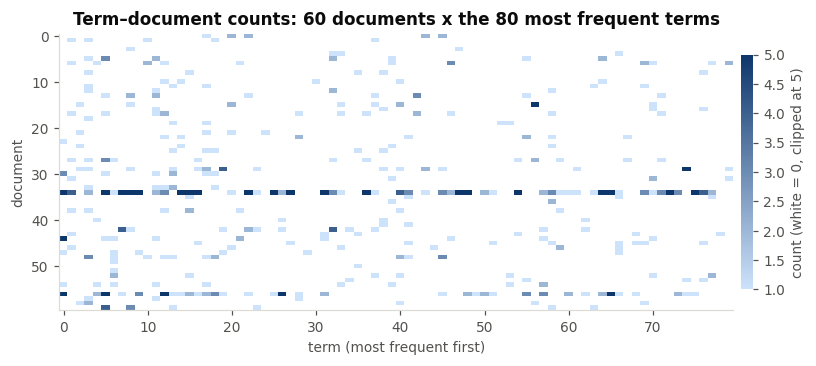

filled cells in this densest corner: 7.3%


In [12]:
top80 = np.asarray(X_ng.sum(axis=0)).ravel().argsort()[::-1][:80]
block = X_ng[:60][:, top80].toarray()

from matplotlib.colors import LinearSegmentedColormap

# zeros are masked so they render pure white — the point of the picture is
# how much of the matrix is nothing at all.
blues = LinearSegmentedColormap.from_list("w02_blues", ["#cde2fb", "#0d366b"])
blues.set_bad("white")

fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(np.ma.masked_equal(np.minimum(block, 5), 0), aspect="auto",
               cmap=blues, vmin=1, vmax=5, interpolation="nearest")
ax.set_title("Term–document counts: 60 documents x the 80 most frequent terms")
ax.set_xlabel("term (most frequent first)")
ax.set_ylabel("document")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01, shrink=0.85)
cb.set_label("count (white = 0, clipped at 5)", color=INK_2)
cb.outline.set_visible(False)
plt.tight_layout()
plt.show()

print(f"filled cells in this densest corner: {(block > 0).mean():.1%}")

### 2.4 The practical controls: `min_df`, `max_df`, `max_features`

You do not choose the vocabulary term by term. You choose it with three dials:

- `min_df` — drop terms appearing in fewer than *n* documents. Kills typos,
  one-off identifiers, and the long tail that can never create similarity.
- `max_df` — drop terms appearing in more than a *fraction* of documents. A term
  in 90% of documents separates nothing; this is a data-driven stopword list.
- `max_features` — a hard cap, keeping the most frequent terms.

Sweep them and watch what actually moves.

In [13]:
rows = []
for kw in [dict(), dict(stop_words="english"), dict(min_df=2), dict(min_df=3),
           dict(min_df=3, max_df=0.5), dict(min_df=3, max_df=0.5, stop_words="english"),
           dict(min_df=3, max_df=0.5, stop_words="english", max_features=2000)]:
    v = CountVectorizer(**kw)
    Xk = v.fit_transform(ng_train.data)
    empty = int((np.diff(Xk.indptr) == 0).sum())
    rows.append({
        "settings": ", ".join(f"{k}={v_!r}" for k, v_ in kw.items()) or "(defaults)",
        "vocab": Xk.shape[1],
        "nnz": Xk.nnz,
        "density": f"{Xk.nnz / (Xk.shape[0] * Xk.shape[1]):.3%}",
        "all-zero rows": empty,
    })
pd.DataFrame(rows)

,settings,vocab,nnz,density,all-zero rows
0,(defaults),22641,153251,0.382%,54
1,stop_words='english',22344,105779,0.267%,57
2,min_df=2,10703,141313,0.744%,55
3,min_df=3,7448,134803,1.020%,56
4,"min_df=3, max_df=0.5",7439,124940,0.947%,57
5,"min_df=3, max_df=0.5, stop_words='english'",7165,87349,0.687%,63
6,"min_df=3, max_df=0.5, stop_words='english', ma...",2000,59596,1.680%,69


Note the last column. Some documents end up with **no vector at all** — an
all-zero row.

Two different causes are mixed in there and they deserve different reactions,
so separate them.

In [14]:
v = CountVectorizer(min_df=3, max_df=0.5, stop_words="english")
Xk = v.fit_transform(ng_train.data)
zero_rows = np.flatnonzero(np.diff(Xk.indptr) == 0)

blank_source = sum(1 for i in zero_rows if not ng_train.data[i].strip())
print(f"all-zero rows                      {len(zero_rows)}")
print(f"  ...source text is literally empty  {blank_source}")
print(f"  ...had text, filtered to nothing   {len(zero_rows) - blank_source}")
print("\nall 12 of the second kind (real text that the vocabulary filters erase):")
for i in zero_rows:
    if ng_train.data[i].strip():
        print("  ", repr(" ".join(ng_train.data[i].split())[:74]))

all-zero rows                      63
  ...source text is literally empty  51
  ...had text, filtered to nothing   12

all 12 of the second kind (real text that the vocabulary filters erase):
   'Anaheim.'
   'what done.'
   '------------------------------------'
   '[...] How ironic.'
   'Ditto here too...'
   'sandiego and graig nettles'
   'of Why'
   'S P H E R I C A L D E S I G N I N G'
   "uhhhh there are only three l's."
   '=========================================================================='
   'was...'
   'Rawley Eastwick'


This is a **vectorization** fact, and it has a geometric consequence we need in
§4: a zero vector has a length but **no direction**. Cosine similarity divides
by the norm, so cosine against an all-zero document is undefined — sklearn
returns 0, which is a convention, not an answer. Anywhere in this notebook that
we compare cosine and Euclidean rankings, we drop these rows, and we say so.

Deleting them is not automatically the right production choice. It is the right
choice *for a demonstration about geometry*, because a point with no direction
cannot participate in an argument about angles.

---

## 3 — Weighting

Raw counts have two problems, and TF-IDF is two separate fixes bolted together.

1. **Within a document**, the tenth occurrence of a term is worth much less than
   the first. → a **TF** transform.
2. **Across documents**, a term in every document discriminates nothing. → an
   **IDF** weight.

### 3.1 TF variants

In [15]:
tf_raw = X_manual.astype(float)
tf_bin = (X_manual > 0).astype(float)
tf_rel = tf_raw / tf_raw.sum(axis=1, keepdims=True)            # length-normalised
tf_log = np.where(tf_raw > 0, 1 + np.log(np.maximum(tf_raw, 1)), 0.0)  # sublinear

j = term_index["payment"]
comp = pd.DataFrame({
    "doc": [f"d{i}" for i in range(len(TOY))],
    "count('payment')": tf_raw[:, j].astype(int),
    "binary": tf_bin[:, j],
    "relative (count/len)": tf_rel[:, j].round(4),
    "sublinear 1+log(tf)": tf_log[:, j].round(4),
})
comp

,doc,count('payment'),binary,relative (count/len),sublinear 1+log(tf)
0,d0,0,0.0,0.0000,0.0000
1,d1,0,0.0,0.0000,0.0000
2,d2,1,1.0,0.1429,1.0000
3,d3,1,1.0,0.3333,1.0000
4,d4,3,1.0,0.4286,2.0986
5,d5,0,0.0,0.0000,0.0000


`d4` says `payment` three times, `d3` once. Raw TF calls `d4` three times as
much about payment; sublinear TF calls it 2.10 times as much
(`1 + ln 3 = 2.0986`); binary calls them equal. Which is right depends on the
task, and that is the point — sklearn exposes it as `sublinear_tf`.

### 3.2 IDF — the textbook formula and the one sklearn actually uses

The textbook definition is

$$\mathrm{idf}(t) = \log \frac{N}{\mathrm{df}(t)}$$

sklearn does **not** compute that. With `smooth_idf=True` (the default) it
computes

$$\mathrm{idf}_{\text{sklearn}}(t) = \ln\!\left(\frac{1+N}{1+\mathrm{df}(t)}\right) + 1$$

Three differences, each with a reason: `+1` inside the log pretends there is one
extra document containing every term, so an unseen term cannot divide by zero;
the trailing `+1` keeps a term appearing in *every* document at weight 1 instead
of 0, so it is de-emphasised rather than deleted; and the log is natural, not
base 10 or 2.

Do not memorise it. Reproduce it, which is what 3.3 does.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

N = len(TOY)
df_counts = (X_manual > 0).sum(axis=0)

idf_textbook = np.log(N / df_counts)
idf_sklearn = np.log((1 + N) / (1 + df_counts)) + 1

tv = TfidfVectorizer(tokenizer=str.split, token_pattern=None)
X_tfidf = tv.fit_transform(TOY)

assert list(tv.get_feature_names_out()) == vocab_manual
assert np.allclose(idf_sklearn, tv.idf_)
print("our smoothed IDF == TfidfVectorizer.idf_   (asserted)\n")

pd.DataFrame({
    "term": vocab_manual,
    "df": df_counts,
    "textbook  ln(N/df)": idf_textbook.round(4),
    "sklearn  ln((1+N)/(1+df))+1": idf_sklearn.round(4),
    "sklearn .idf_": tv.idf_.round(4),
}).sort_values("df", ascending=False).reset_index(drop=True)

our smoothed IDF == TfidfVectorizer.idf_   (asserted)



,term,df,textbook ln(N/df),sklearn ln((1+N)/(1+df))+1,sklearn .idf_
0,the,4,0.4055,1.3365,1.3365
1,payment,3,0.6931,1.5596,1.5596
2,parcel,3,0.6931,1.5596,1.5596
3,late,2,1.0986,1.8473,1.8473
4,arrived,2,1.0986,1.8473,1.8473
5,damaged,2,1.0986,1.8473,1.8473
6,failed,2,1.0986,1.8473,1.8473
7,my,1,1.7918,2.2528,2.2528
8,wipe,1,1.7918,2.2528,2.2528
9,refund,1,1.7918,2.2528,2.2528


Look at `the`, which appears in 4 of 6 documents. The textbook formula gives it
0.4055; sklearn gives 1.3365 — more than three times as much. If you hand-work a
TF-IDF example with the textbook formula and then compare it to sklearn's
output, **every number disagrees**, and the disagreement is not a bug in either.
This is the single most common self-inflicted wound in this material.

### 3.3 Reproduce `TfidfVectorizer` end to end

Counts → multiply by smoothed IDF → L2-normalise each row. That is the whole
pipeline. If our array equals sklearn's to floating-point tolerance, we
understand the transform.

In [17]:
# 1. term frequency (raw counts, because sublinear_tf defaults to False)
M = X_manual.astype(float)

# 2. multiply by the smoothed IDF, column-wise
M = M * idf_sklearn

# 3. L2-normalise each document row (norm="l2" is the default)
M = M / np.linalg.norm(M, axis=1, keepdims=True)

max_err = np.abs(M - X_tfidf.toarray()).max()
assert np.allclose(M, X_tfidf.toarray())
print(f"max abs difference vs TfidfVectorizer: {max_err:.2e}   (asserted allclose)")
print(f"every row now has unit length: {np.allclose(np.linalg.norm(M, axis=1), 1.0)}")

pd.DataFrame(M.round(4), index=[f"d{i}" for i in range(N)], columns=vocab_manual)

max abs difference vs TfidfVectorizer: 1.11e-16   (asserted allclose)
every row now has unit length: True


,a,and,arrived,checkout,cloth,damaged,damp,failed,for,late,leather,my,parcel,payment,refund,the,wipe,with
d0,0.0000,0.3459,0.5672,0.0000,0.0000,0.2836,0.0000,0.0000,0.0000,0.2836,0.0000,0.0000,0.4789,0.0000,0.0000,0.4104,0.0000,0.0000
d1,0.0000,0.0000,0.4880,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4880,0.0000,0.5951,0.4120,0.0000,0.0000,0.0000,0.0000,0.0000
d2,0.0000,0.0000,0.0000,0.0000,0.0000,0.3653,0.0000,0.0000,0.4455,0.0000,0.0000,0.0000,0.3084,0.3084,0.4455,0.5286,0.0000,0.0000
d3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6687,0.0000,0.0000,0.0000,0.0000,0.0000,0.5646,0.0000,0.4838,0.0000,0.0000
d4,0.0000,0.0000,0.0000,0.2966,0.0000,0.0000,0.0000,0.7297,0.0000,0.0000,0.0000,0.0000,0.0000,0.6161,0.0000,0.0000,0.0000,0.0000
d5,0.3968,0.0000,0.0000,0.0000,0.3968,0.0000,0.3968,0.0000,0.0000,0.0000,0.3968,0.0000,0.0000,0.0000,0.0000,0.2354,0.3968,0.3968


Row `d1` is worth a second look: `my` gets the largest weight in the document,
because it is the only term unique to `d1`. TF-IDF rewards rarity, and rarity is
not the same thing as importance — a typo is very rare. `min_df` exists to keep
that from becoming your top feature.

### 3.4 What the weighting does to the ranking of terms

In [18]:
feat = np.array(vocab_manual)
for i in [0, 2, 4]:
    top_c = [str(t) for t in feat[np.argsort(-X_manual[i])][:3]]
    top_t = [str(t) for t in feat[np.argsort(-M[i])][:3]]
    print(f"d{i}: {TOY[i]}")
    print(f"    top by raw count : {top_c}")
    print(f"    top by tf-idf    : {top_t}\n")

d0: the parcel arrived late and the parcel arrived damaged
    top by raw count : ['arrived', 'the', 'parcel']
    top by tf-idf    : ['arrived', 'parcel', 'the']

d2: refund the payment for the damaged parcel
    top by raw count : ['the', 'for', 'refund']
    top by tf-idf    : ['the', 'for', 'refund']

d4: checkout payment failed payment failed payment failed
    top by raw count : ['payment', 'failed', 'checkout']
    top by tf-idf    : ['failed', 'payment', 'checkout']



---

## 4 — Distance and similarity

**This is the core of the week.** We have points. Now: how far apart are two
points, and which notion of "far" matches the question you are asking?

`scipy.spatial.distance` is the teaching surface — it has all of these, named
consistently, and it is worth knowing that `cdist`/`pdist` exist before you
write your own loop.

### 4.1 The Minkowski family

Euclidean and Manhattan are not separate ideas; they are $p = 2$ and $p = 1$ of

$$d_p(a,b) = \left(\sum_i |a_i - b_i|^p\right)^{1/p}$$

As $p$ grows the largest single coordinate difference dominates, and at
$p = \infty$ it is the *only* thing that counts (Chebyshev).

In [19]:
from scipy.spatial import distance

a = np.array([3.0, 4.0, 0.0])
b = np.array([0.0, 0.0, 0.0])

print(f"a = {a}, b = {b}\n")
for p in [1, 1.5, 2, 3, 10, np.inf]:
    d = distance.minkowski(a, b, p=p)
    label = {1: "  (Manhattan)", 2: "  (Euclidean)"}.get(p, "")
    if p == np.inf:
        label = "  (Chebyshev)"
    print(f"  p = {str(p):>4}   d = {d:.4f}{label}")

print(f"\n  |3| + |4|        = {abs(3) + abs(4):.4f}   <- p=1")
print(f"  sqrt(3^2 + 4^2)  = {np.hypot(3, 4):.4f}   <- p=2")
print(f"  max(|3|, |4|)    = {float(max(3, 4)):.4f}   <- p=inf")

a = [3. 4. 0.], b = [0. 0. 0.]

  p =    1   d = 7.0000  (Manhattan)
  p =  1.5   d = 5.5843
  p =    2   d = 5.0000  (Euclidean)
  p =    3   d = 4.4979
  p =   10   d = 4.0220
  p =  inf   d = 4.0000  (Chebyshev)

  |3| + |4|        = 7.0000   <- p=1
  sqrt(3^2 + 4^2)  = 5.0000   <- p=2
  max(|3|, |4|)    = 4.0000   <- p=inf


### 4.2 Dot product vs cosine — and exactly what L2 normalisation does

The dot product $a \cdot b$ mixes two things: how aligned the vectors are and
how long they are. Cosine divides the length back out:

$$\cos(a,b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

Here is the identity worth carrying out of this course. For **unit** vectors
$\hat a, \hat b$:

$$\lVert \hat a - \hat b \rVert^2 = \lVert\hat a\rVert^2 + \lVert\hat b\rVert^2 - 2\,\hat a \cdot \hat b = 2 - 2\cos(a,b)$$

Squared Euclidean distance is a **strictly decreasing function of cosine
similarity** on the unit sphere. So once your vectors are L2-normalised,
Euclidean and cosine produce *the same ranking* — not a similar one, the same
one. Every claim of the form "cosine beats Euclidean for text" is really a claim
about **normalisation**, not about the metric.

In [20]:
rng = np.random.default_rng(SEED)
P = rng.normal(size=(200, 50))
Pn = P / np.linalg.norm(P, axis=1, keepdims=True)

lhs = distance.cdist(Pn[:1], Pn, "sqeuclidean")[0]
rhs = 2 - 2 * (1 - distance.cdist(Pn[:1], Pn, "cosine")[0])
print(f"max |‖a-b‖^2 - (2 - 2cos)| over 200 unit vectors: {np.abs(lhs - rhs).max():.2e}")
assert np.allclose(lhs, rhs)

# and therefore: identical rankings
r_euc = np.argsort(distance.cdist(Pn[:1], Pn, "euclidean")[0])
r_cos = np.argsort(distance.cdist(Pn[:1], Pn, "cosine")[0])
assert np.array_equal(r_euc, r_cos)
print("rankings by Euclidean and by cosine are identical on unit vectors   (asserted)")

# on the un-normalised vectors they are not
r_euc_raw = np.argsort(distance.cdist(P[:1], P, "euclidean")[0])
r_cos_raw = np.argsort(distance.cdist(P[:1], P, "cosine")[0])
agree = (r_euc_raw[:10] == r_cos_raw[:10]).sum()
print(f"without normalisation, top-10 neighbour lists agree on {agree}/10 positions")

max |‖a-b‖^2 - (2 - 2cos)| over 200 unit vectors: 1.33e-15
rankings by Euclidean and by cosine are identical on unit vectors   (asserted)
without normalisation, top-10 neighbour lists agree on 1/10 positions


The picture: L2 normalisation is the projection of every point onto the unit
circle. Direction survives, magnitude is discarded.

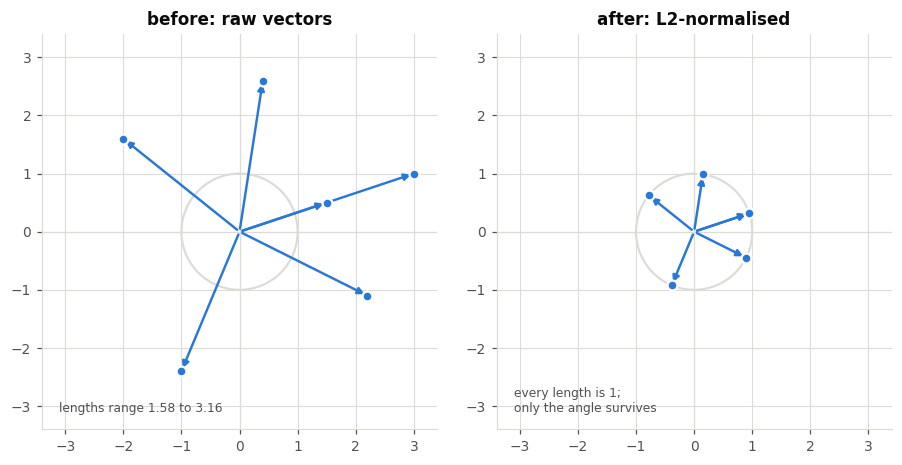

norms before: [3.162 1.581 2.631 2.561 2.6   2.46 ]
norms after : [1. 1. 1. 1. 1. 1.]


In [21]:
V2 = np.array([[3.0, 1.0], [1.5, 0.5], [0.4, 2.6], [-2.0, 1.6], [-1.0, -2.4], [2.2, -1.1]])
V2n = V2 / np.linalg.norm(V2, axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 4.1))
for ax, pts, title in [(axes[0], V2, "before: raw vectors"),
                       (axes[1], V2n, "after: L2-normalised")]:
    circ = plt.Circle((0, 0), 1.0, fill=False, color=GRIDC, linewidth=1.4, zorder=1)
    ax.add_patch(circ)
    for (x, y) in pts:
        ax.annotate("", xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=C_BLUE, lw=1.6))
    ax.scatter(pts[:, 0], pts[:, 1], s=42, color=C_BLUE, zorder=3,
               edgecolor="white", linewidth=1.5)
    ax.set_xlim(-3.4, 3.4); ax.set_ylim(-3.4, 3.4)
    ax.set_aspect("equal"); ax.set_title(title)
    ax.axhline(0, color=GRIDC, lw=0.8); ax.axvline(0, color=GRIDC, lw=0.8)

axes[0].text(-3.1, -3.1, "lengths range 1.58 to 3.16", color=INK_2, fontsize=8)
axes[1].text(-3.1, -3.1, "every length is 1;\nonly the angle survives", color=INK_2, fontsize=8)
plt.tight_layout(); plt.show()

print("norms before:", np.round(np.linalg.norm(V2, axis=1), 3))
print("norms after :", np.round(np.linalg.norm(V2n, axis=1), 3))

### 4.3 A case where cosine and Euclidean rank differently

This is the demonstration the toy corpus was rigged for. Query the raw **count**
matrix — un-normalised, exactly the regime where the two metrics can disagree —
with `"parcel arrived late"`.

In [22]:
q_counts = cv.transform([QUERY]).toarray()[0]

res = pd.DataFrame({
    "doc": [f"d{i}" for i in range(len(TOY))],
    "len (tokens)": [len(d.split()) for d in TOY],
    "euclidean": [distance.euclidean(q_counts, X_manual[i]) for i in range(len(TOY))],
    "cosine sim": [1 - distance.cosine(q_counts, X_manual[i]) for i in range(len(TOY))],
    "text": TOY,
})
res["rank by euclidean"] = res["euclidean"].rank().astype(int)
res["rank by cosine"] = (-res["cosine sim"]).rank(method="min").astype(int)
res.round(4)

,doc,len (tokens),euclidean,cosine sim,text,rank by euclidean,rank by cosine
0,d0,9,2.8284,0.7454,the parcel arrived late and the parcel arrived...,3,2
1,d1,4,1.0000,0.8660,my parcel arrived late,1,1
2,d2,7,3.1623,0.1925,refund the payment for the damaged parcel,4,3
3,d3,3,2.4495,0.0000,the payment failed,2,4
4,d4,7,4.6904,0.0000,checkout payment failed payment failed payment...,6,4
5,d5,7,3.1623,0.0000,wipe the leather with a damp cloth,4,4


In [23]:
by_euc = res.sort_values("euclidean")["doc"].tolist()
by_cos = res.sort_values("cosine sim", ascending=False)["doc"].tolist()
print(f"query: {QUERY!r}\n")
print(f"  ranked by Euclidean distance : {by_euc}")
print(f"  ranked by cosine similarity  : {by_cos}\n")
print(f"  d0 (same topic, verbose) : euclidean {res.loc[0, 'euclidean']:.4f}   "
      f"cosine {res.loc[0, 'cosine sim']:.4f}")
print(f"  d3 (unrelated, terse)    : euclidean {res.loc[3, 'euclidean']:.4f}   "
      f"cosine {res.loc[3, 'cosine sim']:.4f}")

query: 'parcel arrived late'

  ranked by Euclidean distance : ['d1', 'd3', 'd0', 'd2', 'd5', 'd4']
  ranked by cosine similarity  : ['d1', 'd0', 'd2', 'd3', 'd4', 'd5']

  d0 (same topic, verbose) : euclidean 2.8284   cosine 0.7454
  d3 (unrelated, terse)    : euclidean 2.4495   cosine 0.0000


Euclidean puts `d3` — *"the payment failed"*, which shares **not one term** with
the query — ahead of `d0`, which is the same complaint written at length.
Cosine gives `d3` a similarity of exactly 0.0 (orthogonal: no shared terms) and
`d0` a similarity of 0.7454.

The mechanism is not subtle. `d0` is 9 tokens and the query is 3, so the vectors
have very different lengths, and Euclidean charges you for that. **Document
length is not evidence about topic**, and un-normalised Euclidean cannot tell
the difference. This is why text retrieval is a cosine business.

### 4.4 Jaccard and Hamming — sets and binary vectors

Both throw away counts and keep membership.

$$J(A,B) = \frac{|A \cap B|}{|A \cup B|}, \qquad d_H(a,b) = \frac{1}{n}\sum_i [a_i \neq b_i]$$

Jaccard looks only at positions where *at least one* vector is non-zero;
Hamming counts every position, including the ones where both are zero. On sparse
text that difference is enormous — almost every position is a mutual zero, so
Hamming reports everything as nearly identical.

In [24]:
x = np.array([1, 0, 1, 1, 0, 0])
y = np.array([1, 1, 1, 0, 0, 0])
print(f"x = {x}\ny = {y}\n")
print(f"  intersection |A∩B| = {int((x & y).sum())}    union |A∪B| = {int((x | y).sum())}")
print(f"  jaccard similarity = {(x & y).sum() / (x | y).sum():.4f}")
print(f"  scipy jaccard DISTANCE = {distance.jaccard(x, y):.4f}   (= 1 - similarity)")
print(f"  hamming distance       = {distance.hamming(x, y):.4f}   ({int((x != y).sum())} of {len(x)} positions differ)")

# the same two measures on real documents, at three known levels of relatedness
kb_bin = (CountVectorizer(stop_words="english", binary=True)
          .fit_transform(articles["text"]).toarray() > 0).astype(int)
pos = {d: i for i, d in enumerate(articles.doc_id)}

print(f"\nhelp-centre articles as binary vectors over {kb_bin.shape[1]} terms:\n")
print(f"  {'pair':<34}{'shared':>7}{'union':>7}{'jaccard d':>12}{'hamming d':>12}")
for a_id, b_id, label in [("KB017", "KB039", "planted near-duplicate"),
                          ("KB017", "KB018", "both about payments"),
                          ("KB017", "KB031", "unrelated topics")]:
    u, v = kb_bin[pos[a_id]], kb_bin[pos[b_id]]
    print(f"  {a_id}/{b_id} {label:<22}{int((u & v).sum()):7d}{int((u | v).sum()):7d}"
          f"{distance.jaccard(u, v):12.4f}{distance.hamming(u, v):12.4f}")

x = [1 0 1 1 0 0]
y = [1 1 1 0 0 0]

  intersection |A∩B| = 2    union |A∪B| = 4
  jaccard similarity = 0.5000
  scipy jaccard DISTANCE = 0.5000   (= 1 - similarity)
  hamming distance       = 0.3333   (2 of 6 positions differ)

help-centre articles as binary vectors over 540 terms:

  pair                               shared  union   jaccard d   hamming d
  KB017/KB039 planted near-duplicate     23     25      0.0800      0.0037
  KB017/KB018 both about payments         2     43      0.9535      0.0759
  KB017/KB031 unrelated topics            0     52      1.0000      0.0963


Jaccard uses its whole range: 0.08 for the planted duplicate, 0.95 for two
articles that merely share a category, 1.00 for a genuinely unrelated pair.
Hamming reports 0.0037 / 0.0759 / 0.0963 — all tiny, and *increasing* with how
many terms the documents contain rather than with how different they are.
That is what "dominated by mutual zeros" means in practice: with ~540 terms and
25 of them used, agreeing-on-absent is nearly the whole score.

Use Hamming when the vector length is fixed and every position is meaningful —
hash signatures, feature flags, error-correcting codes. Use Jaccard when the
object really is a **set**, which is exactly what §5.3 builds.

### 4.5 Edit (Levenshtein) distance — for strings, not documents

Everything above compares *vectors*. Edit distance compares the **characters of
a string**: the minimum number of insertions, deletions, and substitutions to
turn one into the other. It is the right tool for typo-tolerant lookup, record
linkage, and code matching — and the wrong tool for documents, because it is
O(nm) and it has no notion of a term at all.

The dynamic program is small enough to write, and writing it is the point: cell
$(i,j)$ is the cost of aligning the first $i$ characters of `a` with the first
$j$ of `b`.

In [25]:
def levenshtein_grid(a: str, b: str) -> np.ndarray:
    """Full DP table. D[i, j] = edit distance between a[:i] and b[:j]."""
    n, m = len(a), len(b)
    D = np.zeros((n + 1, m + 1), dtype=int)
    D[:, 0] = np.arange(n + 1)      # delete every char of a
    D[0, :] = np.arange(m + 1)      # insert every char of b
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(
                D[i - 1, j] + 1,                          # deletion
                D[i, j - 1] + 1,                          # insertion
                D[i - 1, j - 1] + (a[i - 1] != b[j - 1]),  # substitution / match
            )
    return D


A, B = "recieve", "receive"
G = levenshtein_grid(A, B)
grid = pd.DataFrame(G, index=[""] + list(A), columns=[""] + list(B))
print(f"levenshtein({A!r}, {B!r}) = {G[-1, -1]}   (bottom-right cell)\n")
grid

levenshtein('recieve', 'receive') = 2   (bottom-right cell)



,,r,e,c,e,i,v,e
,0,1,2,3,4,5,6,7
r,1,0,1,2,3,4,5,6
e,2,1,0,1,2,3,4,5
c,3,2,1,0,1,2,3,4
i,4,3,2,1,1,1,2,3
e,5,4,3,2,1,2,2,2
v,6,5,4,3,2,2,2,3
e,7,6,5,4,3,3,3,2


In [26]:
for u, v in [("recieve", "receive"), ("parcel", "package"),
             ("KB-1029", "KB-1092"), ("refund", "refunded"),
             ("parcel arrived late", "the payment failed")]:
    print(f"  {u!r:24} vs {v!r:22} -> {levenshtein_grid(u, v)[-1, -1]}")

  'recieve'                vs 'receive'              -> 2
  'parcel'                 vs 'package'              -> 5
  'KB-1029'                vs 'KB-1092'              -> 2
  'refund'                 vs 'refunded'             -> 2
  'parcel arrived late'    vs 'the payment failed'   -> 16


`recieve`/`receive` is distance 2: plain Levenshtein has no transposition
operation, so swapping two adjacent letters costs a substitution each way. If
transpositions matter for your task (they do for typo correction), you want
Damerau-Levenshtein, which adds that operation.

The last row is the warning. Two *documents* with no relationship get a small-ish
number because they happen to be similar lengths. Edit distance on documents
measures typing, not meaning.

### 4.6 Jensen–Shannon — for probability distributions

When your vectors are **distributions** (they are non-negative and sum to 1 —
a topic mixture, a normalised term profile, two models' output probabilities),
the right family is information-theoretic. Jensen–Shannon divergence is the
symmetric, always-finite relative of KL divergence; `scipy` returns its square
root, which **is** a metric.

In [27]:
p = np.array([0.50, 0.30, 0.20])
q = np.array([0.40, 0.40, 0.20])
r = np.array([0.05, 0.05, 0.90])

print("three distributions over the same 3 outcomes:")
print(f"  p = {p}\n  q = {q}\n  r = {r}\n")
print(f"  JS distance(p, q) = {distance.jensenshannon(p, q, base=2):.4f}   (similar shapes)")
print(f"  JS distance(p, r) = {distance.jensenshannon(p, r, base=2):.4f}   (very different)")
print(f"  JS distance(q, r) = {distance.jensenshannon(q, r, base=2):.4f}")
print(f"\n  bounded: with base=2 the divergence lies in [0, 1], so the distance does too.")

# on real term distributions
prof = X_manual / X_manual.sum(axis=1, keepdims=True)
print(f"\n  term profiles of d0 and d1 (same topic)    : JS = "
      f"{distance.jensenshannon(prof[0], prof[1], base=2):.4f}")
print(f"  term profiles of d0 and d4 (no shared terms): JS = "
      f"{distance.jensenshannon(prof[0], prof[4], base=2):.4f}   (the maximum)")

three distributions over the same 3 outcomes:
  p = [0.5 0.3 0.2]
  q = [0.4 0.4 0.2]
  r = [0.05 0.05 0.9 ]

  JS distance(p, q) = 0.0958   (similar shapes)
  JS distance(p, r) = 0.6320   (very different)
  JS distance(q, r) = 0.6303

  bounded: with base=2 the divergence lies in [0, 1], so the distance does too.

  term profiles of d0 and d1 (same topic)    : JS = 0.6068
  term profiles of d0 and d4 (no shared terms): JS = 1.0000   (the maximum)


Note the last two numbers, because they are a warning about misapplying this.
Two documents with **no shared terms at all** hit the maximum JS distance of
exactly 1.0, and two documents on the same topic still score 0.6068 — because a
raw term profile is a *sparse* distribution and JS saturates on those. JS is the
right tool when the distributions are smooth and over the same small support
(topic mixtures, class-probability outputs, two models' token distributions),
not for raw term counts. Use it where it fits; do not reach for it because it
sounds sophisticated.

### 4.7 Metric or not?

A **metric** satisfies four axioms: non-negativity, identity of indiscernibles
($d(a,b)=0 \iff a=b$), symmetry, and the **triangle inequality**
$d(a,c) \le d(a,b) + d(b,c)$.

Why care? Because indexing structures — ball trees, metric trees, and a lot of
approximate-nearest-neighbour machinery — use the triangle inequality to *prune*
without checking every point. If your distance is not a metric, those guarantees
evaporate.

Cosine distance ($1 - \cos$) is **not** a metric, and the counterexample is two
dimensions wide.

In [28]:
u = np.array([1.0, 0.0])
v = np.array([1.0, 1.0])
w = np.array([0.0, 1.0])

d_uv, d_vw, d_uw = (distance.cosine(u, v), distance.cosine(v, w), distance.cosine(u, w))
print("cosine distance (1 - cos):")
print(f"  d(u,v) = {d_uv:.4f}   d(v,w) = {d_vw:.4f}   d(u,w) = {d_uw:.4f}")
print(f"  d(u,v) + d(v,w) = {d_uv + d_vw:.4f}  <  d(u,w) = {d_uw:.4f}   -> TRIANGLE INEQUALITY VIOLATED")

# angular distance = arccos(cos)/pi -- this one IS a metric
ang = lambda x, y: np.arccos(np.clip(1 - distance.cosine(x, y), -1, 1)) / np.pi
a_uv, a_vw, a_uw = ang(u, v), ang(v, w), ang(u, w)
print("\nangular distance  arccos(cos)/pi:")
print(f"  d(u,v) = {a_uv:.4f}   d(v,w) = {a_vw:.4f}   d(u,w) = {a_uw:.4f}")
print(f"  d(u,v) + d(v,w) = {a_uv + a_vw:.4f}  >=  d(u,w) = {a_uw:.4f}   -> holds")

cosine distance (1 - cos):
  d(u,v) = 0.2929   d(v,w) = 0.2929   d(u,w) = 1.0000
  d(u,v) + d(v,w) = 0.5858  <  d(u,w) = 1.0000   -> TRIANGLE INEQUALITY VIOLATED

angular distance  arccos(cos)/pi:
  d(u,v) = 0.2500   d(v,w) = 0.2500   d(u,w) = 0.5000
  d(u,v) + d(v,w) = 0.5000  >=  d(u,w) = 0.5000   -> holds


In [29]:
# empirical check across metrics on random non-negative triples
rng = np.random.default_rng(SEED)
T = rng.random((3000, 3, 12))
T[rng.random(T.shape) < 0.6] = 0.0            # make it sparse, like text
T = T[np.all(T.sum(axis=2) > 0, axis=1)]      # drop any all-zero vector

def violation_rate(fn):
    bad = 0
    for a_, b_, c_ in T:
        if fn(a_, c_) > fn(a_, b_) + fn(b_, c_) + 1e-12:
            bad += 1
    return bad / len(T)

checks = {
    "euclidean": distance.euclidean,
    "cityblock (Manhattan)": distance.cityblock,
    "jaccard (on binarised)": lambda p_, q_: distance.jaccard(p_ > 0, q_ > 0),
    "cosine distance (1-cos)": distance.cosine,
    "angular distance": ang,
    "squared euclidean": distance.sqeuclidean,
}
pd.DataFrame([
    {"distance": k, "triangle inequality violated": f"{violation_rate(f):.1%}",
     "is a metric": "no" if violation_rate(f) > 0 else "yes"}
    for k, f in checks.items()
])

,distance,triangle inequality violated,is a metric
0,euclidean,0.0%,yes
1,cityblock (Manhattan),0.0%,yes
2,jaccard (on binarised),0.0%,yes
3,cosine distance (1-cos),1.6%,no
4,angular distance,0.0%,yes
5,squared euclidean,3.2%,no


Squared Euclidean fails too — which is why sklearn is careful to call it
`sqeuclidean` and not "Euclidean". It is fine for *ranking* (it is monotone in
Euclidean) and wrong for anything that needs the axioms.

### 4.8 Choosing — the decision table

| Your data is… | Your question is… | Use | Because |
|---|---|---|---|
| TF-IDF / count vectors | which document is about the same thing? | **cosine** | length is not evidence about topic |
| already L2-normalised | anything | **cosine ≡ Euclidean** | identical rankings (§4.2) — pick whichever your library optimises |
| dense embeddings | nearest neighbour | **cosine** (or dot, if norms are meaningful) | direction carries the semantics |
| sets: shingles, tags, user baskets | how much overlap? | **Jaccard** | ratio over the union; ignores mutual absence |
| fixed-length binary codes | how many bits differ? | **Hamming** | counts every position, including shared zeros |
| strings, IDs, names | is this a typo of that? | **edit distance** | operates on characters, not terms |
| probability distributions | how different are these two profiles? | **Jensen–Shannon** | symmetric, bounded, and its square root is a metric |
| genuinely low-dimensional, comparable units | physical closeness | **Euclidean** | the axioms hold and the intuition is real |

### 4.9 The curse of dimensionality

In high dimensions, distances **concentrate**: the nearest and farthest points
from a query stop being meaningfully different. The standard diagnostic is
**relative contrast**,
$(d_{\max} - d_{\min}) / \bar{d}$ — the spread of distances from a query,
scaled by their average. If it approaches 0, the nearest and the farthest point
are the same distance away and "nearest neighbour" stops meaning anything.

In [30]:
rng = np.random.default_rng(SEED)
dims = [2, 5, 10, 50, 200, 1000, 5000]
rows = []
for d in dims:
    X = rng.random((1000, d))
    q = rng.random((1, d))
    de = distance.cdist(q, X, "euclidean")[0]
    dc = distance.cdist(q, X, "cosine")[0]
    rows.append({
        "dimensions": d,
        "euclidean relative contrast": (de.max() - de.min()) / de.mean(),
        "cosine relative contrast": (dc.max() - dc.min()) / dc.mean(),
    })
conc = pd.DataFrame(rows)
conc.round(3)

,dimensions,euclidean relative contrast,cosine relative contrast
0,2,1.961,4.235
1,5,1.520,3.389
2,10,1.172,2.161
3,50,0.516,0.999
4,200,0.268,0.563
5,1000,0.104,0.231
6,5000,0.056,0.112


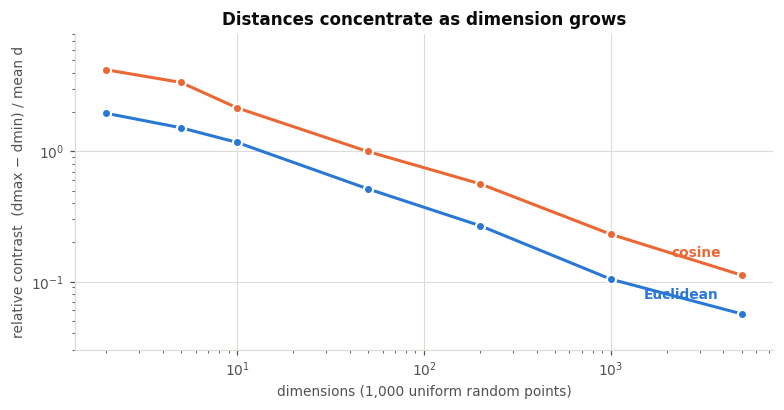

In [31]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.plot(conc["dimensions"], conc["euclidean relative contrast"], "-o",
        color=C_BLUE, lw=2, ms=6, mec="white", mew=1.4)
ax.plot(conc["dimensions"], conc["cosine relative contrast"], "-o",
        color=C_ORANGE, lw=2, ms=6, mec="white", mew=1.4)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("dimensions (1,000 uniform random points)")
ax.set_ylabel("relative contrast  (dmax − dmin) / mean d")
ax.set_title("Distances concentrate as dimension grows")
# two series, so direct labels carry identity and no legend box is needed
ax.annotate("Euclidean", xy=(dims[-1], conc["euclidean relative contrast"].iloc[-1]),
            xytext=(-64, 10), textcoords="offset points", color=C_BLUE,
            fontsize=9, fontweight="bold")
ax.annotate("cosine", xy=(dims[-1], conc["cosine relative contrast"].iloc[-1]),
            xytext=(-46, 12), textcoords="offset points", color=C_ORANGE,
            fontsize=9, fontweight="bold")
ax.set_ylim(0.03, 8)
plt.tight_layout(); plt.show()

Be honest about what this shows: on **dense uniform** data *both* metrics
concentrate — Euclidean contrast falls from 1.96 at two dimensions to 0.056 at
5,000. Cosine holds roughly **twice** the contrast at every dimension, but it
falls just as steeply. The slogan "cosine beats the curse" is too strong.

What actually saves text is not the metric on its own — it is **sparsity plus
normalisation**. Real TF-IDF vectors are not uniform noise: two unrelated
documents share no terms at all, so their cosine similarity is exactly 0, while
related documents sit well above it. The gap survives.

So let us measure the thing we actually care about: does the choice change
retrieval quality on real text? A 5-NN classifier is a direct read on
"do my neighbours look like me".

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_extraction.text import TfidfVectorizer


def fit_drop_empty(vec):
    """Vectorize train/test and drop all-zero rows (see §2.4 — no direction)."""
    A = vec.fit_transform(ng_train.data)
    B = vec.transform(ng_test.data)
    ma, mb = np.diff(A.indptr) > 0, np.diff(B.indptr) > 0
    return A[ma], ng_train.target[ma], B[mb], ng_test.target[mb], (~ma).sum(), (~mb).sum()


rows = []
configs = [
    ("raw counts (un-normalised)", CountVectorizer(min_df=3, max_df=0.5, stop_words="english")),
    ("tf-idf, norm=None", TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english",
                                          sublinear_tf=True, norm=None)),
    ("tf-idf, L2-normalised", TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english",
                                              sublinear_tf=True)),
]
t0 = time.time()
for name, vec in configs:
    Xa, ya, Xb, yb, dropped_tr, dropped_te = fit_drop_empty(vec)
    for metric in ["euclidean", "cosine"]:
        acc = (KNeighborsClassifier(n_neighbors=5, metric=metric, algorithm="brute")
               .fit(Xa, ya).score(Xb, yb))
        rows.append({"representation": name, "metric": metric, "5-NN test accuracy": round(acc, 4)})
print(f"({time.time() - t0:.1f}s;  dropped {dropped_tr} empty train / {dropped_te} empty test rows)")
(pd.DataFrame(rows)
   .pivot(index="representation", columns="metric", values="5-NN test accuracy")
   .reindex([c[0] for c in configs])[["euclidean", "cosine"]])

(0.5s;  dropped 63 empty train / 41 empty test rows)


metric,euclidean,cosine
representation,,
raw counts (un-normalised),0.5435,0.8367
"tf-idf, norm=None",0.5320,0.8832
"tf-idf, L2-normalised",0.8832,0.8832


Three things to read off that table, in order of importance:

1. **On raw counts, the metric is worth ~0.29 accuracy.** Euclidean is crippled
   by document length; cosine is not.
2. **On L2-normalised TF-IDF the two columns are identical to four decimals** —
   which is not a coincidence, it is §4.2's identity. Once you normalise, the
   choice of metric stops mattering, because you already made it.
3. Un-normalised TF-IDF sits in between: the IDF weighting helps Euclidean
   somewhat, but length is still in the vector.

The actionable version: **normalise, then use whichever of cosine or Euclidean
your library makes fastest.** Arguing about the metric while leaving vectors
un-normalised is arguing about the wrong thing.

---

## 5 — Using similarity

Four things you can build the moment you can measure similarity. All four use
the same 44-article synthetic help-centre corpus described in
[`data/README.md`](data/README.md), plus 20 Newsgroups where we need labels.

### 5.1 Nearest-neighbour retrieval

In [33]:
print(articles.category.value_counts().to_string())
articles[["doc_id", "category", "title"]].head(5)

category
shipping        10
payments        10
returns          9
account          8
product_care     7


,doc_id,category,title
0,KB001,shipping,How long does standard shipping take?
1,KB002,shipping,Tracking my parcel
2,KB003,shipping,Do you ship internationally?
3,KB004,shipping,My parcel says delivered but I did not receive it
4,KB005,shipping,Changing the delivery address after ordering


In [34]:
from sklearn.metrics.pairwise import cosine_similarity

kb_vec = TfidfVectorizer(stop_words="english", sublinear_tf=True)
KB = kb_vec.fit_transform(articles["text"])
print(f"TF-IDF matrix: {KB.shape},  density {KB.nnz / np.prod(KB.shape):.2%}")


def search(query: str, k: int = 3):
    sims = cosine_similarity(kb_vec.transform([query]), KB)[0]
    top = np.argsort(-sims)[:k]
    return pd.DataFrame({
        "doc_id": articles.doc_id.values[top],
        "category": articles.category.values[top],
        "title": articles.title.values[top],
        "cosine": sims[top].round(4),
    })


for q in ["how long until my order gets here", "I forgot my password",
          "do I have to pay for return postage", "washing merino"]:
    print(f"\nQ: {q!r}")
    print(search(q).to_string(index=False))

TF-IDF matrix: (44, 540),  density 4.52%

Q: 'how long until my order gets here'
doc_id category                                        title  cosine
 KB040 shipping                           Where is my order?  0.2181
 KB005 shipping Changing the delivery address after ordering  0.2036
 KB001 shipping        How long does standard shipping take?  0.1681

Q: 'I forgot my password'
doc_id category                                 title  cosine
 KB024  account               Resetting your password  0.3455
 KB041  account                      I cannot sign in  0.2888
 KB001 shipping How long does standard shipping take?  0.0000

Q: 'do I have to pay for return postage'
doc_id category                                title  cosine
 KB012  returns                Return shipping costs  0.2810
 KB044 payments           Accepted cards and wallets  0.1822
 KB016 payments Which payment methods do you accept?  0.1719

Q: 'washing merino'
doc_id     category                    title  cosine
 KB032 p

Try the failure case deliberately. A user who does not use your vocabulary gets
nothing, because TF-IDF can only match terms that literally appear.

In [35]:
for q in ["money back for a broken item", "my package never showed up"]:
    sims = cosine_similarity(kb_vec.transform([q]), KB)[0]
    print(f"\nQ: {q!r}   (max cosine over the whole corpus: {sims.max():.4f})")
    print(search(q).to_string(index=False))


Q: 'money back for a broken item'   (max cosine over the whole corpus: 0.1852)
doc_id category                                                   title  cosine
 KB009  returns                                How do I return an item?  0.1852
 KB018 payments Why do I see a pending charge for an order I cancelled?  0.1635
 KB038  returns                                       Starting a return  0.1402

Q: 'my package never showed up'   (max cosine over the whole corpus: 0.2142)
doc_id category                                 title  cosine
 KB037 shipping               Standard delivery times  0.2142
 KB001 shipping How long does standard shipping take?  0.0000
 KB025  account           Changing your email address  0.0000


`"money back"` never appears in the corpus — the articles say `refund`. TF-IDF
scores it 0.185 against the best match, barely above noise, and there is no
amount of tuning that fixes it, because the two phrases share no column. That
is the **vocabulary mismatch** problem, and it is precisely what §6's dense
vectors are for.

### 5.2 Cosine at scale is one matrix multiply

Worth seeing explicitly, because it reframes what a similarity search *is*.
L2-normalise the matrix, and every cosine similarity in the corpus is
$\hat{X}\hat{X}^\top$ — a single GEMM. `sklearn.cosine_similarity` does exactly
this; so does a vector database, with an approximation bolted on so the matrix
never has to be materialised.

In [36]:
from sklearn.preprocessing import normalize

KBn = normalize(KB).toarray().astype(np.float32)      # 44 x V, unit rows
Xt = torch.from_numpy(KBn).to(device)

q_idx = 8
S_torch = (Xt @ Xt.T)                                  # <- the whole thing
top_vals, top_idx = torch.topk(S_torch[q_idx], k=4)

print(f"similarity matrix computed on {device}: {tuple(S_torch.shape)}\n")
print(f"query = {articles.doc_id[q_idx]}  {articles.title[q_idx]!r}\n")
for v, i in zip(top_vals.tolist()[1:], top_idx.tolist()[1:]):
    print(f"  {v:.4f}  {articles.doc_id[i]}  {articles.title[i]}")

# and it agrees with sklearn
assert np.allclose(S_torch.cpu().numpy(), cosine_similarity(KB), atol=1e-5)
print("\ntorch matmul == sklearn cosine_similarity   (asserted)")

similarity matrix computed on mps: (44, 44)

query = KB009  'How do I return an item?'

  0.7869  KB038  Starting a return
  0.3308  KB014  When will my refund appear?
  0.3177  KB042  Refund timing at a glance

torch matmul == sklearn cosine_similarity   (asserted)


In [37]:
# scaling: 20-newsgroups, reduced to 200 dense dimensions (see §5.5)
from sklearn.decomposition import TruncatedSVD

X_big = TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english",
                        sublinear_tf=True).fit_transform(ng_train.data)
Z_big = normalize(TruncatedSVD(200, random_state=SEED).fit_transform(X_big)).astype(np.float32)
Zt = torch.from_numpy(Z_big).to(device)

def sync():
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()


_ = Zt @ Zt.T            # warm-up: first kernel launch pays compilation cost
sync()
t0 = time.time()
S = Zt @ Zt.T            # <- every pairwise cosine, in one call
sync()
dt = time.time() - t0

n = Z_big.shape[0]
print(f"{n} x {n} = {n * n:,} cosine similarities over {Z_big.shape[1]} dims")
print(f"  {dt * 1000:.1f} ms on {device}  ->  {n * n / max(dt, 1e-9) / 1e6:.0f}M similarities/second")
print(f"  the full matrix would be {n * n * 4 / 1e6:.0f} MB in float32 — at 10M documents it is 400 TB,")
print(f"  which is why real systems approximate instead of materialising it.")

1774 x 1774 = 3,147,076 cosine similarities over 200 dims
  0.8 ms on mps  ->  3969M similarities/second
  the full matrix would be 13 MB in float32 — at 10M documents it is 400 TB,
  which is why real systems approximate instead of materialising it.


### 5.3 Near-duplicate detection with Jaccard on shingles

A help centre accumulates duplicates: a page copied for a regional site, an old
draft left un-deleted after a rewrite, a landing-page excerpt. Duplicates poison
retrieval (your top-3 becomes the same answer three times) and inflate any
count you take over the corpus.

**Shingling** turns a document into a *set* of overlapping k-grams, which
restores a little word order — the thing bag-of-words threw away in §1 — and
then Jaccard measures set overlap.

Our corpus has **8 planted near-duplicate pairs**, produced by three documented
edit operations of decreasing overlap (`data/make_support_articles.py`). So we
have ground truth, and we can score the detector instead of admiring it.

In [38]:
TOKEN_RE = re.compile(r"[a-z0-9]+")


def word_shingles(text: str, k: int = 3) -> set:
    w = TOKEN_RE.findall(text.lower())
    return {" ".join(w[i:i + k]) for i in range(len(w) - k + 1)}


def char_shingles(text: str, k: int = 5) -> set:
    s = re.sub(r"\s+", " ", text.lower())
    return {s[i:i + k] for i in range(len(s) - k + 1)}


def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a or b) else 0.0


demo = word_shingles(TOY[1])
print(f"word 3-shingles of {TOY[1]!r}:")
for s in sorted(demo):
    print("   ", s)

# ground truth from the generator
TRUTH = {tuple(sorted((i, pos[r.near_dup_of])))
         for i, r in articles.iterrows() if r.near_dup_of}
print(f"\nplanted near-duplicate pairs: {len(TRUTH)} of "
      f"{len(articles) * (len(articles) - 1) // 2} possible pairs")

word 3-shingles of 'my parcel arrived late':
    my parcel arrived
    parcel arrived late

planted near-duplicate pairs: 8 of 946 possible pairs


In [39]:
def score_all(shingler):
    S = [shingler(t) for t in articles["text"]]
    out = [(jaccard(S[i], S[j]), i, j)
           for i, j in itertools.combinations(range(len(S)), 2)]
    out.sort(reverse=True)
    return out


scored = {"word 3-shingles": score_all(word_shingles),
          "char 5-shingles": score_all(char_shingles)}

top = scored["word 3-shingles"][:11]
pd.DataFrame([{
    "jaccard": round(s, 4),
    "planted?": "YES" if (i, j) in TRUTH else "—",
    "edit kind": (articles.edit_kind[j] or articles.edit_kind[i]) if (i, j) in TRUTH else "",
    "A": f"{articles.doc_id[i]} {articles.title[i]}",
    "B": f"{articles.doc_id[j]} {articles.title[j]}",
} for s, i, j in top])

,jaccard,planted?,edit kind,A,B
0,0.8806,YES,synonym_swap,KB017 My card was declined,KB039 Payment declined at checkout
1,0.6301,YES,reorder_trim,KB024 Resetting your password,KB041 I cannot sign in
2,0.5694,YES,excerpt,KB014 When will my refund appear?,KB042 Refund timing at a glance
3,0.5256,YES,synonym_swap,KB001 How long does standard shipping take?,KB037 Standard delivery times
4,0.5132,YES,synonym_swap,KB009 How do I return an item?,KB038 Starting a return
5,0.4684,YES,reorder_trim,KB002 Tracking my parcel,KB040 Where is my order?
6,0.4310,YES,excerpt,KB016 Which payment methods do you accept?,KB044 Accepted cards and wallets
7,0.3492,YES,excerpt,KB032 Washing merino wool,KB043 Merino wash instructions
8,0.0667,—,,KB009 How do I return an item?,KB042 Refund timing at a glance
9,0.0636,—,,KB009 How do I return an item?,KB014 When will my refund appear?


All 8 planted pairs are the top 8, and then there is a cliff: 0.3492 for the
weakest true duplicate, 0.0667 for the strongest false one. That gap is what
makes a threshold possible at all. Sweep it and you get the precision/recall
curve the business actually has to choose a point on.

In [40]:
rows = []
for name, sc in scored.items():
    for th in [0.05, 0.10, 0.20, 0.30, 0.35, 0.40, 0.50, 0.60]:
        pred = {(i, j) for s, i, j in sc if s >= th}
        tp = len(pred & TRUTH)
        rows.append({
            "shingles": name, "threshold": th, "flagged": len(pred),
            "precision": round(tp / len(pred), 3) if pred else float("nan"),
            "recall": round(tp / len(TRUTH), 3),
        })
(pd.DataFrame(rows)
   .pivot(index="threshold", columns="shingles", values=["flagged", "precision", "recall"])
   .reindex(columns=list(scored), level=1))

flagged                       precision                          recall                
shingles  word 3-shingles char 5-shingles word 3-shingles char 5-shingles word 3-shingles char 5-shingles
threshold                                                                                                
0.05                 10.0           273.0             0.8           0.029           1.000           1.000
0.10                  8.0            47.0             1.0           0.170           1.000           1.000
0.20                  8.0             8.0             1.0           1.000           1.000           1.000
0.30                  8.0             8.0             1.0           1.000           1.000           1.000
0.35                  7.0             8.0             1.0           1.000           0.875           1.000
0.40                  7.0             7.0             1.0           1.000           0.875           0.875
0.50                  5.0             6.0             1.0           1.000           0.625           0.750
0.60                  2.0             5.0             1.0           1.000           0.250           0.625

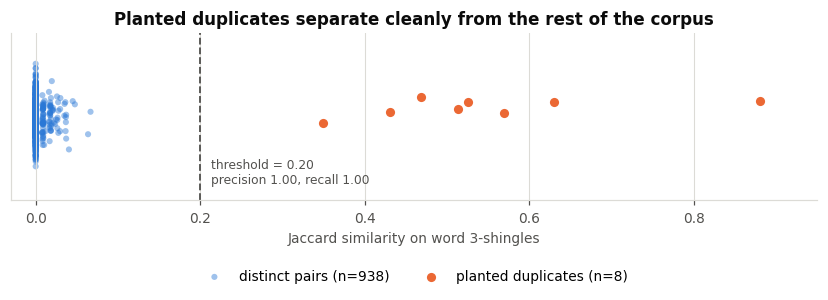

In [41]:
fig, ax = plt.subplots(figsize=(7.6, 3.1))
sc = scored["word 3-shingles"]
rng = np.random.default_rng(SEED)
neg = np.array([s for s, i, j in sc if (i, j) not in TRUTH])
posv = np.array([s for s, i, j in sc if (i, j) in TRUTH])

ax.scatter(neg, rng.normal(0, 0.06, len(neg)), s=16, color=C_BLUE, alpha=0.45,
           edgecolor="none", label=f"distinct pairs (n={len(neg)})")
ax.scatter(posv, rng.normal(0, 0.06, len(posv)), s=52, color=C_ORANGE,
           edgecolor="white", linewidth=1.2, zorder=3,
           label=f"planted duplicates (n={len(posv)})")
ax.axvline(0.20, color=INK_2, lw=1.2, ls="--")
ax.annotate("threshold = 0.20\nprecision 1.00, recall 1.00", xy=(0.20, -0.20),
            xytext=(7, 0), textcoords="offset points", fontsize=8, color=INK_2,
            va="center")
ax.set_yticks([]); ax.set_ylim(-0.30, 0.30)
ax.set_xlim(-0.03, 0.95)
ax.set_xlabel("Jaccard similarity on word 3-shingles")
ax.set_title("Planted duplicates separate cleanly from the rest of the corpus")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.34))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Two honest caveats before anyone ships this:

- The gap is this clean because the corpus is small and the duplicates were
  manufactured. On a real corpus the distributions overlap and the threshold is
  a genuine business decision — how many false merges can you tolerate?
- We compared **all 946 pairs**. That is $O(n^2)$; at a million documents it is
  half a trillion comparisons. The standard fix is MinHash + locality-sensitive
  hashing, which estimates Jaccard from a short signature and only compares
  candidates that collide in a hash bucket.

### 5.4 k-means over TF-IDF

Unsupervised structure. 20 Newsgroups has labels, so we can score the clustering
with **Adjusted Rand Index** — the labels are used for *evaluation only*, never
for fitting.

In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

tfidf_ng = TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english", sublinear_tf=True)
Xc = tfidf_ng.fit_transform(ng_train.data)
keep = np.diff(Xc.indptr) > 0                      # §2.4: drop directionless rows
Xc, yc = Xc[keep], ng_train.target[keep]
print(f"clustering {Xc.shape[0]} documents x {Xc.shape[1]} terms "
      f"(dropped {(~keep).sum()} empty)")

km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xc)
ari_tfidf = adjusted_rand_score(yc, km.labels_)
nmi_tfidf = normalized_mutual_info_score(yc, km.labels_)
print(f"\nk-means on raw TF-IDF:   ARI = {ari_tfidf:.4f}   NMI = {nmi_tfidf:.4f}")

clustering 1711 documents x 7165 terms (dropped 63 empty)

k-means on raw TF-IDF:   ARI = 0.3748   NMI = 0.4382


In [43]:
terms = np.array(tfidf_ng.get_feature_names_out())
order = km.cluster_centers_.argsort()[:, ::-1]
for c in range(3):
    members = yc[km.labels_ == c]
    major = np.bincount(members, minlength=3).argmax()
    purity = np.bincount(members, minlength=3).max() / len(members)
    print(f"cluster {c}  (n={len(members):4d}, mostly {ng_train.target_names[major]}, "
          f"purity {purity:.0%})")
    print("   ", ", ".join(terms[order[c, :10]]))

cluster 0  (n= 434, mostly comp.graphics, purity 90%)
    thanks, graphics, know, files, file, program, does, looking, help, hi
cluster 1  (n= 926, mostly sci.space, purity 59%)
    space, just, like, think, don, nasa, time, know, make, does
cluster 2  (n= 351, mostly rec.sport.baseball, purity 98%)
    year, game, team, games, think, hit, baseball, runs, good, pitching


The top terms are recognisable, but ARI ≈ 0.37 is mediocre. k-means minimises
squared Euclidean distance, and on a 7,000-dimensional sparse matrix that is
exactly the regime §4.9 warned about. §5.5 does something about it.

### 5.5 LSA / SVD — a dense compression of the sparse matrix

Truncated SVD factors the term-document matrix and keeps the top $k$ singular
directions:

$$X \approx U_k \Sigma_k V_k^\top$$

The rows of $U_k\Sigma_k$ are documents in a $k$-dimensional **latent** space
where each axis is a weighted blend of correlated terms, not a single term. That
is the point: `car` and `automobile` co-occur with the same neighbours, so they
end up loading on the same latent direction, and two documents can now be
similar without sharing a single word.

Applied to TF-IDF this is called **Latent Semantic Analysis**. Two operational
notes: `TruncatedSVD` works directly on sparse input (unlike `PCA`, which would
have to centre and therefore densify), and you should **re-normalise afterwards**
— the projection does not preserve unit length, and §4.2 says that matters.

In [44]:
svd = TruncatedSVD(n_components=200, random_state=SEED)
Z = svd.fit_transform(Xc)
Zn = normalize(Z)

print(f"{Xc.shape[1]} sparse dimensions -> {Z.shape[1]} dense dimensions "
      f"({Xc.shape[1] / Z.shape[1]:.0f}x smaller)")
print(f"variance explained by 200 components: {svd.explained_variance_ratio_.sum():.1%}")
for k in [1, 2, 10, 50, 100, 200]:
    print(f"  first {k:3d}: {svd.explained_variance_ratio_[:k].sum():.1%}")

7165 sparse dimensions -> 200 dense dimensions (36x smaller)
variance explained by 200 components: 33.6%
  first   1: 0.3%
  first   2: 1.1%
  first  10: 3.9%
  first  50: 12.7%
  first 100: 21.0%
  first 200: 33.6%


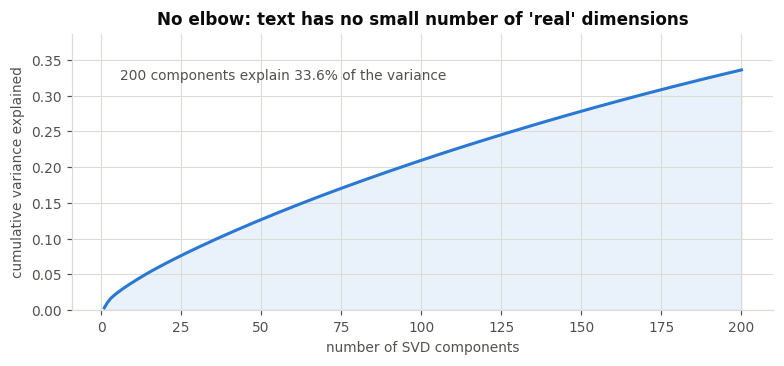

In [45]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
cum = np.cumsum(svd.explained_variance_ratio_)
ax.plot(np.arange(1, len(cum) + 1), cum, color=C_BLUE, lw=2)
ax.fill_between(np.arange(1, len(cum) + 1), 0, cum, color=C_BLUE, alpha=0.10)
ax.set_xlabel("number of SVD components")
ax.set_ylabel("cumulative variance explained")
ax.set_title("No elbow: text has no small number of 'real' dimensions")
ax.set_ylim(0, max(0.3, cum[-1] * 1.15))
ax.text(6, cum[-1] * 0.96, f"200 components explain {cum[-1]:.1%} of the variance",
        color=INK_2, fontsize=9)
plt.tight_layout(); plt.show()

Note what the curve does *not* have: an elbow. There is no natural cut point, so
`n_components` is a budget you set, not a truth you discover. Two hundred
components explain about a third of the variance — and, as the next cell shows,
clustering still improves substantially. "Explained variance" is not the metric
that matters here; downstream task performance is.

In [46]:
km_lsa = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Zn)
ari_lsa = adjusted_rand_score(yc, km_lsa.labels_)
nmi_lsa = normalized_mutual_info_score(yc, km_lsa.labels_)

pd.DataFrame([
    {"representation": f"TF-IDF, {Xc.shape[1]} sparse dims", "ARI": round(ari_tfidf, 4),
     "NMI": round(nmi_tfidf, 4)},
    {"representation": f"LSA, {Z.shape[1]} dense dims (renormalised)", "ARI": round(ari_lsa, 4),
     "NMI": round(nmi_lsa, 4)},
])

,representation,ARI,NMI
0,"TF-IDF, 7165 sparse dims",0.3748,0.4382
1,"LSA, 200 dense dims (renormalised)",0.6043,0.6117


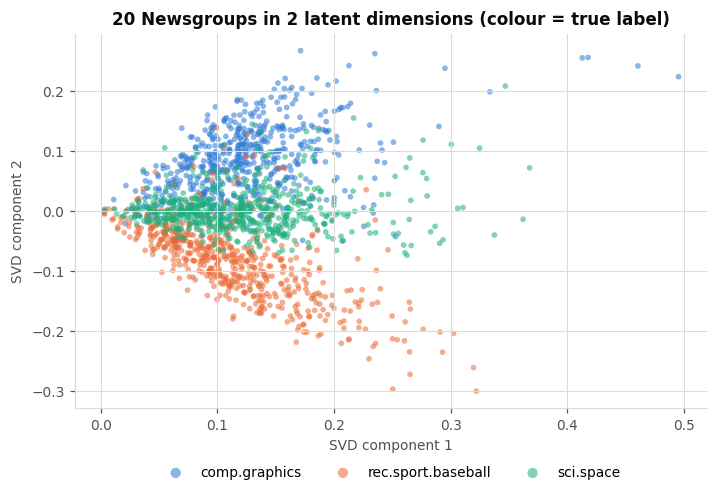

variance explained by these 2 components: 1.1%
correlation(component 1, number of distinct terms in the document) = 0.652
mean position per class:
  comp.graphics          comp1 +0.123   comp2 +0.081
  rec.sport.baseball     comp1 +0.114   comp2 -0.082
  sci.space              comp1 +0.121   comp2 +0.001


In [47]:
svd2 = TruncatedSVD(n_components=2, random_state=SEED)
Z2 = svd2.fit_transform(Xc)

fig, ax = plt.subplots(figsize=(6.6, 4.6))
for c, name in enumerate(ng_train.target_names):
    m = yc == c
    ax.scatter(Z2[m, 0], Z2[m, 1], s=14, alpha=0.55, color=SERIES[c],
               edgecolor="none", label=name)
ax.set_xlabel("SVD component 1"); ax.set_ylabel("SVD component 2")
ax.set_title("20 Newsgroups in 2 latent dimensions (colour = true label)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, markerscale=1.8)
plt.tight_layout(); plt.show()

print(f"variance explained by these 2 components: {svd2.explained_variance_ratio_.sum():.1%}")
nnz_per_doc = np.diff(Xc.indptr)
print(f"correlation(component 1, number of distinct terms in the document) = "
      f"{np.corrcoef(Z2[:, 0], nnz_per_doc)[0, 1]:.3f}")
print("mean position per class:")
for c, name in enumerate(ng_train.target_names):
    print(f"  {name:22s} comp1 {Z2[yc == c, 0].mean():+.3f}   comp2 {Z2[yc == c, 1].mean():+.3f}")

Read the numbers under the plot rather than the plot. Component 1 correlates
0.652 with how many distinct terms a document has, and all three class means sit
on top of each other at ≈ +0.12 — it is mostly a *document size* axis. The
classes only start to separate on component 2, and these two components together
carry 1.1% of the variance. Do not over-read a 2-d projection of a
7,000-dimensional space; it is a sanity check, not evidence.

**Where LSA stops.** It is a single global linear map. A word gets exactly one
row in $V$, so `bank` cannot mean two things; the components have no guaranteed
interpretation; and adding documents means refactoring. The next section shows a
better *word* representation with the same fundamental limit — and that limit is
what the rest of the course exists to remove.

### 5.6 The branch: a classifier on TF-IDF (+ SVD)

Everything above *compared* documents. But a document vector is just a row of
features — so the models you already know from ISM 6251 can train on it. One
logistic regression, run twice: once on the sparse TF-IDF matrix, once on a
200-dimensional SVD compression like §5.5's.

Note `transform`, not `fit_transform`, on the test set: new documents must be
placed on the **same fitted axes** (§1.2's rule, now load-bearing). Week 3
starts from this cell and runs the whole toolkit.

In [ ]:
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english", sublinear_tf=True)
Xtr = vec.fit_transform(ng_train.data)   # fit the axes on train ONLY
Xte = vec.transform(ng_test.data)        # test docs get the SAME fitted axes

clf = LogisticRegression(max_iter=1000).fit(Xtr, ng_train.target)
print("TF-IDF, 7,165 dims:", round(clf.score(Xte, ng_test.target), 3))

svd = TruncatedSVD(n_components=200, random_state=SEED)
Ztr = svd.fit_transform(Xtr)             # compress: 7,165 columns -> 200
Zte = svd.transform(Xte)

clf2 = LogisticRegression(max_iter=1000).fit(Ztr, ng_train.target)
print("LSA,      200 dims:", round(clf2.score(Zte, ng_test.target), 3))

TF-IDF, 7,165 dims: 0.897
LSA,      200 dims: 0.903


---

## 6 — Preview of next class: dense static embeddings

> **Moved to Week 3.** We did not cover this section in class — giving words
> their own vectors is where *next* week begins, alongside training models on
> this week's document vectors. Everything below is optional preview; none of
> it is on Quiz 2 or in Assignment 2.

> *"You shall know a word by the company it keeps."* — J. R. Firth, 1957

The **distributional hypothesis**: words that appear in similar contexts have
similar meanings. TF-IDF cannot exploit that — `refund` and `reimbursement` are
different columns and that is the end of it. word2vec and GloVe learn a dense
vector per word *from co-occurrence statistics*, so words used alike end up
near each other.

We are **consumers** here. We are not going to derive skip-gram with negative
sampling; we are going to load pretrained vectors, use them, and find out
exactly where they stop working.

In [48]:
with np.load(GLOVE_SRC, allow_pickle=True) as f:
    GLOVE_WORDS = f["words"]
    GLOVE_VECS = f["vectors"].astype(np.float32)

W_INDEX = {w: i for i, w in enumerate(GLOVE_WORDS)}
GLOVE_UNIT = GLOVE_VECS / np.linalg.norm(GLOVE_VECS, axis=1, keepdims=True)

print(f"GloVe subset: {GLOVE_VECS.shape[0]:,} words x {GLOVE_VECS.shape[1]} dimensions "
      f"({GLOVE_VECS.nbytes / 1e6:.1f} MB in float32)")
print(f"most frequent 12 words: {list(GLOVE_WORDS[:12])}")
print(f"\nvector for 'refund' (first 8 of 100 dims):\n  {GLOVE_VECS[W_INDEX['refund']][:8]}")

GloVe subset: 15,095 words x 100 dimensions (6.0 MB in float32)
most frequent 12 words: ['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', "'s", 'for', '-']

vector for 'refund' (first 8 of 100 dims):
  [ 0.2744 -0.2087  0.484  -0.5266 -0.2881  0.2722 -0.2002  0.8218]


Two things to notice immediately. It is **dense** — no zeros, unlike every
vector so far. And it is **100 numbers instead of 7,165**: the whole vocabulary
of §5 compressed into a vector shorter than a tweet.

### 6.1 Nearest neighbours — does the geometry mean anything?

In [49]:
def nearest(vec: np.ndarray, k: int = 6, exclude=()) -> list:
    sims = GLOVE_UNIT @ (vec / np.linalg.norm(vec))
    out = []
    for i in np.argsort(-sims):
        w = GLOVE_WORDS[i]
        if w in exclude:
            continue
        out.append((str(w), round(float(sims[i]), 4)))
        if len(out) == k:
            return out
    return out


for w in ["refund", "parcel", "leather", "battery", "apple"]:
    print(f"{w:9s} -> {nearest(GLOVE_VECS[W_INDEX[w]], k=5, exclude={w})}")

refund    -> [('refunds', 0.8476), ('payment', 0.7108), ('refunded', 0.6727), ('fees', 0.6411), ('checks', 0.6368)]
parcel    -> [('parcels', 0.7857), ('leased', 0.5462), ('freight', 0.5368), ('cargo', 0.5079), ('warehouse', 0.5038)]
leather   -> [('shoes', 0.7397), ('cloth', 0.7119), ('boots', 0.7082), ('pants', 0.703), ('jacket', 0.6969)]
battery   -> [('batteries', 0.8111), ('electric', 0.5771), ('lithium', 0.5708), ('assault', 0.5658), ('powered', 0.5635)]
apple     -> [('microsoft', 0.7449), ('ibm', 0.6822), ('intel', 0.6778), ('software', 0.6775), ('dell', 0.6741)]


`refund` sits next to `refunds`, `payment`, `refunded`, `fees` — exactly the
neighbourhood §5.1's vocabulary-mismatch failure needed. Nothing here was told
what a refund is; this fell out of co-occurrence counts over Wikipedia and
Gigaword.

`apple` is the caution: its neighbours are `microsoft`, `ibm`, `intel`, `dell`.
The corpus talked about the company far more than the fruit, so the vector *is*
the company. A static embedding gives every word exactly one vector, and that
vector is whichever sense dominated the training data.

### 6.2 The analogy demo

The famous property: some semantic relations show up as roughly parallel
displacements, so `king − man + woman` lands near `queen`.

In [50]:
def analogy(a: str, b: str, c: str, k: int = 3):
    """a is to b as ? is to c   ->   vec(a) - vec(b) + vec(c)"""
    v = GLOVE_VECS[W_INDEX[a]] - GLOVE_VECS[W_INDEX[b]] + GLOVE_VECS[W_INDEX[c]]
    return nearest(v, k=k, exclude={a, b, c})


for a, b, c in [("king", "man", "woman"), ("paris", "france", "italy"),
                ("walking", "walk", "swim"), ("bigger", "big", "small")]:
    print(f"{a:8s} - {b:8s} + {c:8s} = {analogy(a, b, c)}")

king     - man      + woman    = [('queen', 0.7834), ('monarch', 0.6934), ('throne', 0.6833)]
paris    - france   + italy    = [('rome', 0.8084), ('milan', 0.7317), ('naples', 0.709)]
walking  - walk     + swim     = [('swimming', 0.8063), ('surfing', 0.66), ('rowing', 0.6436)]
bigger   - big      + small    = [('larger', 0.8778), ('smaller', 0.8575), ('large', 0.7902)]


Now run one more, and read the output as evidence rather than as a party trick.

In [51]:
print(f"doctor   - man      + woman    = {analogy('doctor', 'man', 'woman')}")
print(f"engineer - man      + woman    = {analogy('engineer', 'man', 'woman')}")

doctor   - man      + woman    = [('nurse', 0.7757), ('physician', 0.7128), ('doctors', 0.6794)]
engineer - man      + woman    = [('technician', 0.6593), ('educator', 0.6148), ('surgeon', 0.5957)]


The embedding is not making a mistake. It is reporting, accurately, that in the
text it was trained on, the words near `doctor` in male-associated contexts and
the words near `nurse` in female-associated contexts are distributed that way.
**The geometry encodes the corpus, including its biases**, and any system you
build on top of these vectors inherits them — a résumé screener built on this
representation will behave accordingly. This is not a footnote; it is a property
of the method. It is also why every serious deployment needs the measurement
discipline this course builds toward.

### 6.3 Averaging word vectors into a document vector

The obvious way to get a document vector: average the word vectors. It is one
line, it is fast, and it is genuinely weak. Let us find out how weak.

In [52]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

kb_idf = dict(zip(kb_vec.get_feature_names_out(), kb_vec.idf_))
MAX_IDF = float(kb_vec.idf_.max())


def embed_mean(text: str) -> np.ndarray:
    ws = [w for w in TOKEN_RE.findall(text.lower()) if w in W_INDEX]
    return GLOVE_VECS[[W_INDEX[w] for w in ws]].mean(0) if ws else np.zeros(100, np.float32)


def embed_idf(text: str) -> np.ndarray:
    """IDF-weighted mean with stopwords removed — the usual first improvement."""
    ws = [w for w in TOKEN_RE.findall(text.lower())
          if w in W_INDEX and w not in ENGLISH_STOP_WORDS]
    if not ws:
        return np.zeros(100, np.float32)
    wt = np.array([kb_idf.get(w, MAX_IDF) for w in ws], dtype=np.float32)
    return (GLOVE_VECS[[W_INDEX[w] for w in ws]] * wt[:, None]).sum(0) / wt.sum()


E_mean = np.stack([embed_mean(t) for t in articles["text"]])
E_idf = np.stack([embed_idf(t) for t in articles["text"]])

iu = np.triu_indices(len(articles), 1)
rows = []
for name, S in [(f"TF-IDF (sparse, {KB.shape[1]} dims)", cosine_similarity(KB)),
                ("GloVe plain mean (100 dims)", cosine_similarity(E_mean)),
                ("GloVe IDF-weighted mean", cosine_similarity(E_idf))]:
    v = S[iu]
    rows.append({"representation": name, "mean pairwise cosine": round(v.mean(), 3),
                 "min": round(v.min(), 3), "max": round(v.max(), 3),
                 "std": round(v.std(), 3)})
pd.DataFrame(rows)

,representation,mean pairwise cosine,min,max,std
0,"TF-IDF (sparse, 540 dims)",0.050,0.000,0.979,0.090
1,GloVe plain mean (100 dims),0.951,0.809,0.999,0.031
2,GloVe IDF-weighted mean,0.800,0.417,0.998,0.108


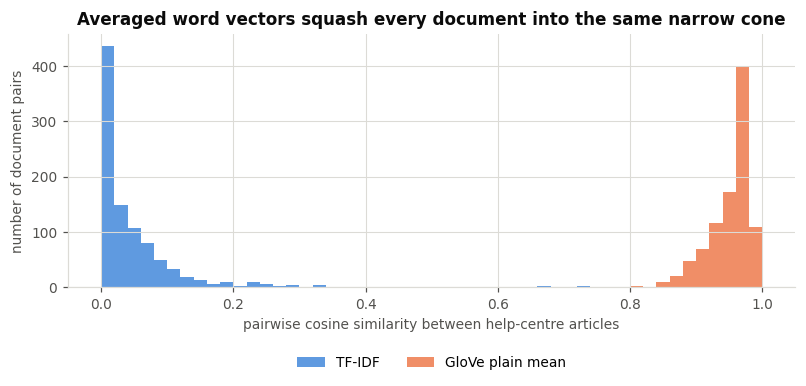

In [53]:
fig, ax = plt.subplots(figsize=(7.4, 3.7))
bins = np.linspace(0, 1, 51)
ax.hist(cosine_similarity(KB)[iu], bins=bins, color=C_BLUE, alpha=0.75,
        label="TF-IDF")
ax.hist(cosine_similarity(E_mean)[iu], bins=bins, color=C_ORANGE, alpha=0.75,
        label="GloVe plain mean")
ax.set_xlabel("pairwise cosine similarity between help-centre articles")
ax.set_ylabel("number of document pairs")
ax.set_title("Averaged word vectors squash every document into the same narrow cone")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

That is the diagnosis. Under TF-IDF the mean pairwise similarity between two
random help articles is 0.05 — unrelated documents look unrelated. Under a plain
GloVe average it is 0.951, and the *minimum* over all 946 pairs is 0.809. An
article about washing wool and an article about two-factor authentication are
0.8 similar. Averaging 50 word vectors mostly recovers the corpus centroid; the
document-specific signal is a small perturbation on top of it.

IDF weighting plus stopword removal helps a lot (mean drops to 0.800, spread
triples) but does not change the character of the problem.

So is it useless? No — it fixes exactly the failure TF-IDF could not.

In [54]:
def top_hits(sims: np.ndarray, k: int = 3) -> str:
    top = np.argsort(-sims)[:k]
    return "  ".join(f"{articles.doc_id[i]} {articles.title[i][:34]!r} ({sims[i]:.3f})"
                     for i in top)


for q in ["money back for a broken item", "my package never showed up",
          "two factor authentication"]:
    s_sparse = cosine_similarity(kb_vec.transform([q]), KB)[0]
    s_dense = cosine_similarity(embed_idf(q).reshape(1, -1), E_idf)[0].astype(float)
    print(f"\nQ: {q!r}")
    print("   TF-IDF :", top_hits(s_sparse))
    print("   GloVe  :", top_hits(s_dense))


Q: 'money back for a broken item'
   TF-IDF : KB009 'How do I return an item?' (0.185)  KB018 'Why do I see a pending charge for ' (0.163)  KB038 'Starting a return' (0.140)
   GloVe  : KB013 'My item arrived damaged' (0.865)  KB014 'When will my refund appear?' (0.821)  KB012 'Return shipping costs' (0.819)

Q: 'my package never showed up'
   TF-IDF : KB037 'Standard delivery times' (0.214)  KB001 'How long does standard shipping ta' (0.000)  KB025 'Changing your email address' (0.000)
   GloVe  : KB042 'Refund timing at a glance' (0.767)  KB038 'Starting a return' (0.760)  KB013 'My item arrived damaged' (0.757)

Q: 'two factor authentication'
   TF-IDF : KB026 'Turning on two factor authenticati' (0.482)  KB001 'How long does standard shipping ta' (0.000)  KB025 'Changing your email address' (0.000)
   GloVe  : KB026 'Turning on two factor authenticati' (0.723)  KB023 'Is my card data stored securely?' (0.577)  KB024 'Resetting your password' (0.552)


Read the three cases carefully, because they are three different lessons:

- **`"money back for a broken item"`** — TF-IDF's best hit is *"How do I return
  an item?"*, matched purely on the word `item`. GloVe finds *"My item arrived
  damaged"* and *"When will my refund appear?"*: no shared vocabulary, right
  answer. **Dense wins.**
- **`"my package never showed up"`** — GloVe returns *"Refund timing at a
  glance"* first. Plausible-adjacent, wrong. TF-IDF matched `package` literally
  and found the delivery article. **Sparse wins.**
- **`"two factor authentication"`** — both find the right article; TF-IDF is the
  more confident and would not have been fooled by anything.

Neither representation dominates. Lexical matching is unbeatable on exact terms,
names, and codes; dense vectors are unbeatable on paraphrase. Systems that need
both run both and combine the results.

### 6.4 The limit: one word, one vector

Everything in §6 shares a single defect, and it is structural rather than a
matter of tuning.

In [55]:
v_bank = GLOVE_VECS[W_INDEX["bank"]]
print("nearest neighbours of 'bank':")
for w, s in nearest(v_bank, k=8, exclude={"bank"}):
    print(f"    {s:.4f}  {w}")

for probe in ["river", "shore", "financial"]:
    sim = float(GLOVE_UNIT[W_INDEX["bank"]] @ GLOVE_UNIT[W_INDEX[probe]])
    print(f"\ncos('bank', {probe!r}) = {sim:.4f}")

print("\nSentence A: 'I deposited a cheque at the bank'")
print("Sentence B: 'We sat on the grassy bank of the river'")
same = np.array_equal(GLOVE_VECS[W_INDEX["bank"]], GLOVE_VECS[W_INDEX["bank"]])
print(f"vector used for 'bank' in A and in B is the same array: {same}")

nearest neighbours of 'bank':
    0.8057  banks
    0.7531  banking
    0.7038  credit
    0.6940  investment
    0.6777  financial
    0.6688  securities
    0.6645  lending
    0.6485  funds

cos('bank', 'river') = 0.3345

cos('bank', 'shore') = 0.5113

cos('bank', 'financial') = 0.6777

Sentence A: 'I deposited a cheque at the bank'
Sentence B: 'We sat on the grassy bank of the river'
vector used for 'bank' in A and in B is the same array: True


`bank` has one vector, and it is the financial one — `banks`, `banking`,
`credit`, `investment`. Its similarity to `financial` is 0.678 and to `river`
just 0.334. The river sense has been averaged away, and *there is no argument you
can pass to get it back*, because the model has no place to put a context. A
static embedding is a lookup table: same word in, same 100 numbers out, whether
the sentence is about a cheque or a riverbank.

That is the cliff we go off next. The fix is a model that reads the *sentence*
and produces a different vector for `bank` in each one — which requires
architectures that process sequences in order, and that is where the course goes
from here.

Note the through-line: **the cosine similarity in this cell is the same cosine
similarity from §4.2.** The vectors get much better over the remaining weeks.
The geometry does not change.

---

## 7 — What to carry forward

**Representation.**

- A term–document matrix makes documents into points; the axes are terms and
  they are unordered, so word order is gone until we fix it architecturally.
- Text matrices are ~0.7% dense. Sparse storage is not an optimisation, it is
  the only way the matrix exists.
- `min_df` / `max_df` / `max_features` are the vocabulary controls, and they can
  leave a document with an **all-zero row** — a point with no direction, which
  cosine cannot score.

**Weighting.**

- TF-IDF is two independent fixes: damp within-document repetition, and
  down-weight terms that appear everywhere.
- sklearn's IDF is $\ln\frac{1+N}{1+\mathrm{df}} + 1$, **not** $\log\frac{N}{\mathrm{df}}$,
  and the output is L2-normalised per row. We reproduced it exactly in §3.3;
  reproduce it yourself before you trust a hand-worked example.

**Geometry.**

- On raw counts, Euclidean confuses *length* with *dissimilarity*: it ranked a
  document sharing zero terms with the query above one on the same topic (§4.3).
- On **L2-normalised** vectors, $\lVert \hat a - \hat b \rVert^2 = 2 - 2\cos$,
  so Euclidean and cosine give identical rankings — verified to four decimals on
  real data in §4.9. The real decision is *normalise or not*, not *which metric*.
- Jaccard for sets, Hamming for fixed-length binary codes, edit distance for
  strings, Jensen–Shannon for distributions. Cosine distance is **not** a metric;
  angular distance is.
- Distances concentrate in high dimensions. Sparsity plus normalisation is what
  keeps text usable, not the metric alone.

**Applications.**

- Retrieval, near-duplicate detection (Jaccard on shingles, with a threshold you
  must *choose* and *measure*), k-means, and LSA — LSA lifted clustering ARI from
  0.37 to 0.60 here, by giving k-means a dense space it can actually work in.

**Preview — next class (§6, not covered today).**

- GloVe puts `refund` next to `payment` without being told what either means,
  and it inherits the corpus's biases while doing it.
- Averaging word vectors into a document vector compresses every document into a
  narrow cone (mean pairwise cosine 0.951 vs TF-IDF's 0.050). It is a baseline,
  not an answer.
- One word, one vector. `bank` is financial and cannot be anything else.

**Next.** These vectors are now features. The immediate question is whether the
classifiers you already know can predict something useful from them — and after
that, what it takes to build a representation that knows `"not good"` is not
`"good"`.